## Execução local
Selecione o kernel **Python (FASE7)** e execute em ordem. Consulte `README_LOCAL.md` para instalação. Redes neurais usam PyTorch/CUDA; operações NumPy, áudio e modelos scikit-learn usam CPU.

In [ ]:
from pathlib import Path
import os, sys
# Localiza FASE7 tanto a partir do projeto quanto da pasta do notebook.
base = Path.cwd().resolve()
FASE7 = next((p for a in (base, *base.parents) for p in (a, a / "FASE7", a / "ANO1" / "FASE7") if p.name == "FASE7" and (p / "RNN").is_dir()), None)
if FASE7 is None:
    raise FileNotFoundError("Abra o Jupyter dentro da pasta FIAP ou FASE7.")
sys.path.insert(0, str(FASE7))
os.chdir(FASE7 / '.')
print("Pasta de trabalho:", Path.cwd())
from fase7_torch import DEVICE
print("Dispositivo:", DEVICE)
from fase7_torch import configurar_ffmpeg
configurar_ffmpeg()


# LIVE 02. Síntese e Reconhecimento de Voz com Deep Learning

Aqui o objetivo é diferente. Vamos rodar código, validar numericamente os conceitos, comparar abordagens clássicas e modernas, e contextualizar tudo no histórico científico de quase um século de pesquisa em fala digital.

A estrutura segue uma ordem cronológica. Começamos pelos fundamentos do som, passamos pelos marcos históricos de cada técnica, e terminamos com aplicações práticas e um caso integrador real. Cada bloco mistura narrativa, código executável e reflexão sobre o que muda quando a técnica vai para produção.

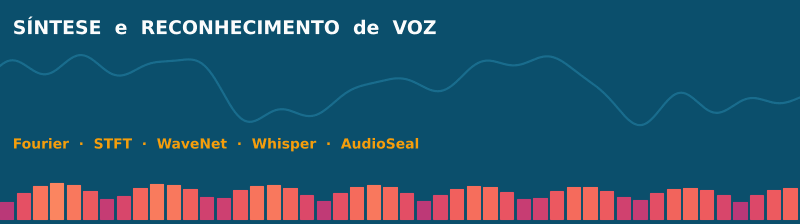

## Indice

1. Por que voz importa agora
2. Linha do tempo da fala digital
3. Fundamentos do som: amplitude, frequência, sample rate
4. Da Transformada de Fourier ao espectrograma
5. Espectrogramas em tempo curto e a escala Mel
6. Da fala humana para a máquina
7. Sintese de voz: do Voder ao WaveNet
8. Reconhecimento de fala: da Audrey ao Whisper
9. Ruido e sua remocao com deep learning
10. Aumento de dados em audio
11. Métricas WER e CER, e o teste de round trip
12. Esteganografia de audio: da teoria ao codigo escondido
13. Caso integrador: o reCAPTCHA de áudio
14. Sintese final e referências

---
## Secao 0. Setup do ambiente

A celula abaixo instala todos os pacotes necessarios. E idempotente, ou seja, se ja estiver instalado o pip apenas confirma. Em Colab fresco, a primeira execucao leva cerca de dois minutos.

In [ ]:
print("Instale as dependências seguindo README_LOCAL.md antes de executar este notebook.")

In [ ]:
# Imports padronizados para o resto do notebook.
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display, Markdown
import os, math, time, warnings, glob, json, urllib.request, wave

warnings.filterwarnings("ignore")
np.random.seed(42)

# Configuracao visual padrao para os graficos
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print(f"numpy {np.__version__}, librosa {librosa.__version__}")

---
## Secao 1. Por que voz importa agora

Voz é a interface mais antiga da humanidade e provavelmente será a mais comum daqui em diante. O que mudou nos últimos quatro anos nao foi a importância da voz, foi a possibilidade real de construir produtos baseados nela sem time gigante de PhDs.

Três números ajudam a dimensionar o momento. O Whisper, modelo open source da OpenAI publicado em setembro de 2022, foi treinado em **680 mil horas** de audio multilingue. Para efeito de comparacao, o DeepSpeech original da Baidu (2014) usou cerca de 7.000 horas, e a Audrey, primeiro reconhecedor de fala que funcionou de verdade, em 1952, reconhecia apenas dez digitos ditos por um único falante.

Em paralelo, sistemas comerciais de transcricao em ingles atingem hoje Word Error Rate **abaixo de 5 por cento** em audio limpo, valor que era considerado magico ate 2015. E ja existem cerca de **8,4 bilhoes** de assistentes de voz ativos no mundo (estimativa Statista 2024), mais do que pessoas no planeta.

A consequência prática e que o ciclo entre prototipo e produção em voz hoje cabe em uma tarde. O que faz diferenca para o engenheiro nao e mais ter acesso ao modelo, e sim entender os fundamentos que tornam aquele modelo bom ou ruim para o caso especifico do cliente.

Diagram of Baidu's DeepSpeech model

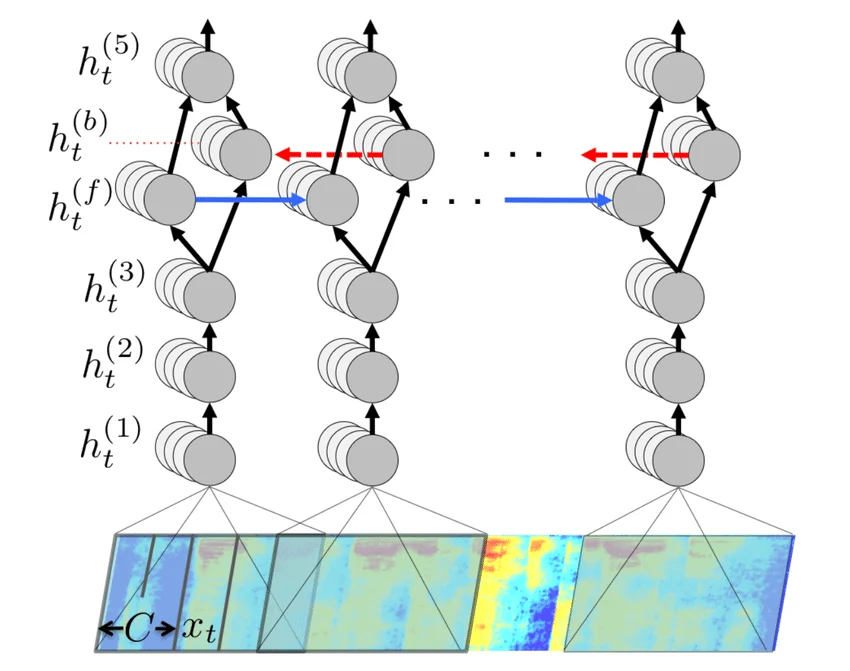

AUDREY (Automatic Digit Recognizer), desenvolvido pelos laboratórios Bell (Bell Labs) em 1952

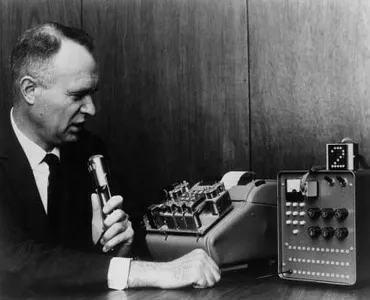

### Onde voz entrega valor hoje

A tabela abaixo resume os setores onde projetos de voz com deep learning tem retorno claro, com empresas e produtos de referencia.

| Setor | Aplicacao | Produtos de referencia |
|---|---|---|
| Call center | Transcricao em tempo real, sumarizacao, deteccao de sentimento, compliance | Genesys, NICE, Five9, AWS Connect |
| Saúde | Transcricao medica, dictado, prontuario por voz | Nuance Dragon Medical (Microsoft) |
| Acessibilidade | Legendas automaticas, conversao para fala, comunicacao para deficiência motora | Otter.ai, Live Transcribe, Voiceitt |
| Automotivo | Assistente embarcado offline com latencia abaixo de 500 ms | Cerence (Mercedes, BMW, Toyota) |
| Biometria | Autenticacao por voz em call center bancario | Pindrop, Nuance |
| Conteudo | Dublagem por IA, audiobooks, narracao de video curto | ElevenLabs, Resemble AI |

---
## Secao 2. Linha do tempo da fala digital

A pesquisa em fala digital atravessa setenta e cinco anos, e cada decada teve uma virada de paradigma. Entender essa cronologia ajuda a localizar o que cada tecnica resolve, e por que algumas voltam a ser usadas mesmo apos ondas mais modernas terem aparecido.

O recorte abaixo cobre os marcos que ressoam ate hoje no codigo de producao. As referencias completas estao na Secao 14.

### Cronologia integrada

| Ano | Bloco | Autor ou instituicao | Marco |
|---|---|---|---|
| 1822 | Matematica | Joseph Fourier | Theorie analytique de la chaleur, base da analise espectral |
| 1939 | TTS | Homer Dudley (Bell Labs) | Voder, primeiro sintetizador eletronico de fala demonstrado na Feira Mundial |
| 1952 | STT | Davis, Biddulph, Balashek (Bell Labs) | Audrey, reconhece digitos isolados de um unico falante |
| 1965 | Matematica | Cooley e Tukey (Bell Labs e Princeton) | FFT, algoritmo que viabiliza o processamento espectral em maquina |
| 1971 | STT | Raj Reddy (CMU), DARPA SUR | Sistema Harpy, mil palavras com beam search |
| 1979 | Ruido | Steven F. Boll (USAF, Univ. Utah) | Subtracao espectral, base do denoising classico |
| 1980 | Features | Davis e Mermelstein | MFCC, features padrao por quarenta anos |
| 1984 | Ruido | Yariv Ephraim e David Malah (Technion) | Estimador MMSE-STSA, refinamento bayesiano do Boll |
| 1989 | STT | Lawrence Rabiner (Bell Labs) | Tutorial sobre HMM, define a era GMM-HMM |
| 1996 | Estego | Bender, Gruhl, Morimoto, Lu (IBM e MIT Media Lab) | Techniques for Data Hiding, IBM Systems Journal |
| 1996 | Estego | Gruhl, Lu, Bender (MIT) | Echo Hiding, robusto a MP3 |
| 1997 | Estego | Cox, Kilian, Leighton, Shamoon (NEC e MIT) | Spread Spectrum Watermarking |
| 2012 | STT | Hinton, Deng, Yu, Dahl et al. | DNN para modelo acustico, reduz WER em 10 a 30 por cento |
| 2014 | STT | Hannun et al. (Baidu Research) | Deep Speech, RNN end to end com CTC |
| 2016 | Ataque | Carlini et al. (Berkeley e Georgetown) | Hidden Voice Commands, audio inintelegivel para humano e valido para STT |
| 2016 | TTS | van den Oord et al. (DeepMind) | WaveNet, modela waveform amostra a amostra |
| 2017 | reCAPTCHA | Bock, Patel, Hughey, Levin (Univ. Maryland) | unCaptcha, 85,15 por cento de sucesso em 5,42 s |
| 2017 | TTS | Wang et al. (Google) | Tacotron e Tacotron 2, texto para mel-spec, vocoder neural |
| 2017 | Ataque | Zhang et al. (Zhejiang) | DolphinAttack, comandos ultrassonicos para assistentes |
| 2018 | Ruido | Jean-Marc Valin (Mozilla, Xiph.Org) | RNNoise, hibrido DSP e DL em tempo real |
| 2018 | Ataque | Carlini e Wagner (Berkeley) | Audio Adversarial Examples, 100 por cento de sucesso em DeepSpeech |
| 2020 | STT | Baevski et al. (Meta AI) | wav2vec 2.0, pre-treino auto-supervisionado em audio cru |
| 2022 | STT | Radford et al. (OpenAI) | Whisper, 680 mil horas multilingue |
| 2024 | Estego | San Roman, Fernandez et al. (Meta AI) | AudioSeal, marca d agua neural localizada (ICML 24) |
| 2024 | Estego | Google DeepMind | SynthID Audio, marca d agua em Lyria e NotebookLM |

Note como cada bloco tem um marco pre deep learning e uma virada com DL. O caso unCaptcha de 2017, que vamos reproduzir na Secao 13, ja combinava pre-processamento classico com STT moderno, exatamente a sequencia de etapas que vamos cobrir nas secoes seguintes.

 	Jean Baptiste Joseph Fourier (1768 - 1830)

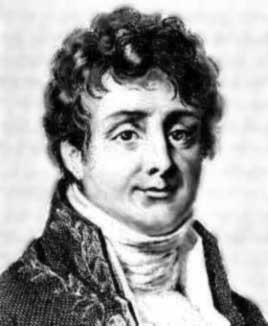

---
## Secao 3. Fundamentos do som

Em 1822, Joseph Fourier publicou no tratado *Theorie analytique de la chaleur* a ideia que sustenta toda a pesquisa moderna em audio. Ele demonstrou que qualquer sinal periodico bem comportado pode ser escrito como uma soma de senoides de diferentes frequencias e amplitudes. Esse resultado, hoje conhecido como Serie de Fourier, e a chave para tudo que vem depois. Quando o aluno olha um espectrograma e ve faixas horizontais brilhantes, ele esta vendo o teorema de Fourier renderizado.

Antes de chegar la, vamos construir manualmente uma senoide pura, que e o tijolo basico do som. As proximas celulas executam tres atos. Primeiro construimos a senoide. Depois visualizamos no dominio do tempo. Por fim, ouvimos.

In [ ]:
# Construindo uma senoide pura.
# A nota La 4 do piano fica em 440 Hz, padrao internacional desde 1939 (ISO 16).
# Vamos amostrar essa nota em 16 kHz, que e a taxa de amostragem usada por
# quase todo modelo de fala moderno (Whisper, wav2vec, Tacotron usam 16 ou 22050).

frequencia = 440.0     # Hz, frequencia da onda
sample_rate = 16000    # Hz, amostras por segundo. Veja o teorema de Nyquist abaixo.
duracao = 1.0          # segundos

# Eixo temporal: array de pontos discretos de 0 ate duracao
t = np.linspace(0, duracao, int(sample_rate * duracao), endpoint=False)

# A senoide pura: y(t) = A * sin(2 pi f t)
# Amplitude 0.5 deixa headroom para nao saturar quando somarmos com outras senoides depois
y_senoide = 0.5 * np.sin(2 * np.pi * frequencia * t)

print(f"Sinal criado: {len(y_senoide)} amostras, ~{duracao:.0f}s a {sample_rate} Hz")
print(f"Valor minimo: {y_senoide.min():.3f}, maximo: {y_senoide.max():.3f}")

In [ ]:
# Visualizando a forma de onda no dominio do tempo.
# Limitamos a janela a 20 ms para que os ciclos individuais fiquem visiveis.
# Em 20 ms a 440 Hz cabem cerca de 8,8 ciclos.

plt.figure()
janela = int(0.02 * sample_rate)  # primeiros 20 ms do sinal
plt.plot(t[:janela] * 1000, y_senoide[:janela], linewidth=1.5)
plt.xlabel("tempo em milissegundos")
plt.ylabel("amplitude")
plt.title("Senoide pura de 440 Hz, primeiros 20 ms")
plt.show()

In [ ]:
# Reproduzindo o La 4. O navegador renderiza o sinal e voce ouve uma flauta sintetica.
display(Audio(y_senoide, rate=sample_rate))

**Observacao sobre o teorema de Nyquist.** Em 1928, Harry Nyquist mostrou que para representar fielmente uma frequencia *f* em forma digital, e preciso amostrar a pelo menos *2f*. Como a fala humana tem energia significativa ate cerca de 8 kHz, 16 kHz e o minimo confortavel para STT. O Whisper faz downsample para 16 kHz internamente, mesmo se voce mandar audio em 44,1 kHz. Por isso usar mais que 16 kHz para fala costuma ser desperdicio de banda.

In [ ]:
# Variando frequencia e amplitude. Tres senoides em frequencias diferentes,
# todas com a mesma duracao, para a turma comparar tom (frequencia) e volume (amplitude).

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, freq in zip(axes, [220, 440, 880]):
    sinal = 0.5 * np.sin(2 * np.pi * freq * t)
    ax.plot(t[:janela] * 1000, sinal[:janela])
    ax.set_ylabel(f"{freq} Hz")
    ax.set_ylim(-1, 1)
axes[-1].set_xlabel("tempo em milissegundos")
fig.suptitle("Mesma forma, diferentes frequencias. Note como o numero de ciclos cresce")
plt.tight_layout()
plt.show()

for freq in [220, 440, 880]:
    sinal = 0.5 * np.sin(2 * np.pi * freq * t)
    print(f"Tocando {freq} Hz:")
    display(Audio(sinal, rate=sample_rate))

In [ ]:
# Amplitude muda volume, nao tom. Tres versoes da mesma senoide com amplitudes
# diferentes. Faca o teste auditivo: o tom e o mesmo, so o volume muda.

for amplitude in [0.1, 0.5, 0.9]:
    sinal = amplitude * np.sin(2 * np.pi * 440 * t)
    print(f"Amplitude {amplitude}:")
    display(Audio(sinal, rate=sample_rate))

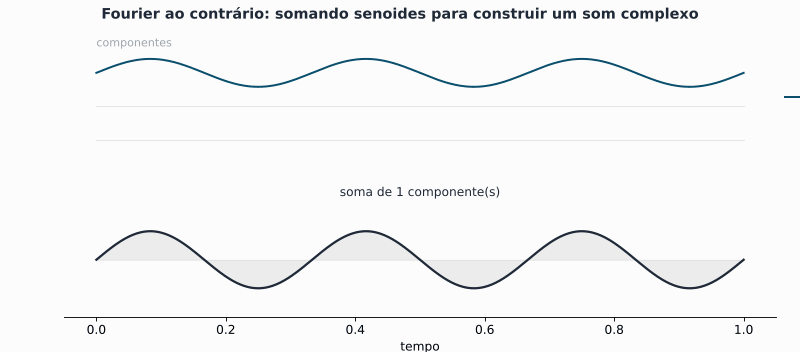

#### 📚 Fundamentos: timbre é a receita de harmônicos

A animação acima constrói um som somando uma **fundamental** $f_0$ com seus **harmônicos** $2f_0, 3f_0, \dots$. Essa é a Série de Fourier escrita ao contrário:

$$x(t) = \sum_{k=1}^{\infty} A_k \sin(2\pi k f_0 t + \phi_k)$$

Duas consequências diretas para voz:

- **Altura (pitch)** é dada por $f_0$ — a taxa de vibração das pregas vocais (~85–180 Hz em vozes masculinas, ~165–255 Hz em femininas).
- **Timbre** é o conjunto de amplitudes $A_k$. É por isso que a mesma nota soa diferente num violino e numa flauta, e que você reconhece a voz de alguém ao telefone: o cérebro lê o padrão de harmônicos.

Os **formantes** (picos largos de energia impostos pela ressonância da boca e nariz) é que distinguem as vogais. Um /a/ e um /i/ têm o mesmo $f_0$ se cantados na mesma nota, mas formantes diferentes. Todo modelo acústico de STT, no fundo, aprende a ler esse mapa de formantes ao longo do tempo.

In [ ]:
# Soma de senoides. Um som real, como uma voz humana, nunca e uma frequencia pura.
# E sempre uma soma ponderada de muitas frequencias.
# Vamos construir um acorde de La Maior: La (440), Do sustenido (554,37), Mi (659,25).

la = 0.4 * np.sin(2 * np.pi * 440.00 * t)
do_sus = 0.4 * np.sin(2 * np.pi * 554.37 * t)
mi = 0.4 * np.sin(2 * np.pi * 659.25 * t)

acorde = la + do_sus + mi

plt.figure()
plt.plot(t[:janela] * 1000, acorde[:janela], linewidth=1.5)
plt.xlabel("tempo em milissegundos")
plt.ylabel("amplitude")
plt.title("Acorde de La Maior, soma de tres senoides")
plt.show()

display(Audio(acorde, rate=sample_rate))

**Por que isso importa para fala.** A voz humana nao e uma senoide pura, e sim um espectro complexo com uma frequencia fundamental (vinda da vibracao das pregas vocais) e dezenas de harmonicos e formantes (vindos da ressonancia da boca, nariz e garganta). Cada vogal tem um padrao caracteristico de formantes que o cerebro reconhece. O modelo acustico de qualquer STT, internamente, esta aprendendo a discriminar esses padroes de formantes ao longo do tempo.

---
## Secao 4. Da Transformada de Fourier ao espectrograma

A Transformada de Fourier converte um sinal do dominio do tempo para o dominio da frequencia. Onde antes voce via amplitude variando no tempo, agora voce ve qual e a contribuicao de cada frequencia ao sinal inteiro.

Em 1965, James Cooley (IBM) e John Tukey (Princeton) publicaram o algoritmo FFT, *Fast Fourier Transform*, que reduziu o custo computacional de O(N²) para O(N log N). Esse algoritmo viabilizou processamento espectral em maquinas reais, e segue sendo um dos algoritmos numericos mais usados do mundo. Toda biblioteca de audio moderna chama uma FFT por baixo dos panos.

Vamos validar numericamente a teoria. Se a FFT funciona, ela deve apontar exatamente as frequencias que estao no sinal.

## Transformada de Fourier, exemplo aplicado

A Transformada de Fourier converte um sinal do dominio do tempo para o dominio
da frequencia. Em vez de dizer qual era a amplitude do som em cada instante,
ela diz quais frequencias compoem o som e com que intensidade.

### A intuicao em uma linha

Qualquer sinal periodico bem comportado pode ser escrito como soma de senoides
de diferentes frequencias e amplitudes. A Transformada de Fourier descobre
quais sao essas senoides.

### A formula da Transformada de Fourier Discreta

Para um sinal amostrado $x[n]$ com $N$ amostras, a DFT (Discrete Fourier Transform) e:

$$ X[k] = \sum_{n=0}^{N-1} x[n] \cdot e^{-j 2 \pi k n / N} $$

Onde $X[k]$ e um numero complexo. A magnitude $|X[k]|$ diz a forca da
frequencia $f_k = k \cdot f_s / N$ no sinal, sendo $f_s$ a taxa de amostragem.

### Exemplo numerico passo a passo

Suponha que voce gravou um diapasao com sample rate $f_s = 8000$ Hz e capturou
$N = 8000$ amostras (ou seja, 1 segundo de audio).

O diapasao vibra na nota La 4, que e 440 Hz. O sinal e aproximadamente:

$$ x[n] = \sin\left(2\pi \cdot 440 \cdot \frac{n}{8000}\right) $$

Aplicando a DFT, voce calcula $X[k]$ para todos os $k$ de 0 a 7999. Quando
voce plota $|X[k]|$ em funcao de $f_k$, ve isto:

In [ ]:
# FFT de uma senoide pura. O resultado deve ter um pico em 440 Hz e quase nada
# no resto. Esse e o teste empirico que conecta teoria a codigo.

# Recriando a senoide de 440 Hz para autocontencao do bloco
y_440 = 0.5 * np.sin(2 * np.pi * 440 * t)

# rfft = FFT para sinais reais. Mais eficiente que a FFT complexa para audio.
fft_resultado = np.fft.rfft(y_440)
magnitudes = np.abs(fft_resultado)
freqs = np.fft.rfftfreq(len(y_440), 1 / sample_rate)

plt.figure()
plt.plot(freqs, magnitudes, linewidth=1.5)
plt.xlim(0, 1000)
plt.xlabel("frequencia em Hz")
plt.ylabel("magnitude")
plt.title("FFT de senoide pura de 440 Hz")
plt.show()

# Confirmacao numerica: onde fica o pico de magnitude?
freq_dominante = freqs[np.argmax(magnitudes)]
print(f"Frequencia detectada pela FFT: {freq_dominante:.2f} Hz")

In [ ]:
acorde

In [ ]:
# FFT do acorde de La Maior. Esperamos tres picos em 440, 554,37 e 659,25 Hz.

fft_acorde = np.fft.rfft(acorde)
mag_acorde = np.abs(fft_acorde)

plt.figure()
plt.plot(freqs, mag_acorde, linewidth=1.5)
plt.xlim(0, 1000)
plt.xlabel("frequencia em Hz")
plt.ylabel("magnitude")
plt.title("FFT do acorde de La Maior, tres picos esperados")
plt.show()

# Picos detectados pela FFT
picos_idx = np.argsort(mag_acorde)[-3:][::-1]  # tres maiores magnitudes
print("Tres picos detectados:")
for idx in sorted(picos_idx, key=lambda i: freqs[i]):
    print(f"  {freqs[idx]:.2f} Hz, magnitude {mag_acorde[idx]:.1f}")

In [ ]:
# FFT de ruido branco. Por definicao, ruido branco distribui energia igualmente
# em todas as frequencias. O espectro precisa ser aproximadamente plano.

ruido = np.random.normal(0, 0.3, len(t))
fft_ruido = np.fft.rfft(ruido)
mag_ruido = np.abs(fft_ruido)

plt.figure()
plt.plot(freqs, mag_ruido, linewidth=0.7, alpha=0.7)
plt.xlim(0, 8000)
plt.xlabel("frequencia em Hz")
plt.ylabel("magnitude")
plt.title("FFT de ruido branco, distribuicao plana")
plt.show()

**O problema do espectro estatico.** A FFT diz quais frequencias estao presentes no sinal inteiro, mas nao diz **quando** cada frequencia aparece. Se voce fizer FFT de tres segundos de fala, o resultado mistura todas as vogais e consoantes em uma soma de frequencias. Isso e inutil para reconhecer palavras. A solucao foi proposta por Dennis Gabor em 1946 e e o que vamos explorar a seguir.

---
## Secao 5. Espectrogramas em tempo curto e a escala Mel

Em 1946, o engenheiro hungaro Dennis Gabor publicou *Theory of communication*, no qual propos analisar sinais em janelas curtas, calculando uma FFT separada para cada janela. Isso da a *Short-Time Fourier Transform*, ou STFT. O resultado nao e mais uma curva, e uma matriz. Linha e frequencia, coluna e tempo, cor e energia naquele instante naquela frequencia.

Esse formato 2D tem uma consequencia profunda. Audio virou imagem. E onde tem imagem, entra CNN. E exatamente assim que arquiteturas como WaveNet, Tacotron, Whisper e Wav2Vec usam o audio como entrada.

Vamos construir um sinal didatico chamado *chirp*, que varre frequencias linearmente. Se a STFT funciona, o espectrograma vai mostrar uma linha diagonal subindo da esquerda para a direita.

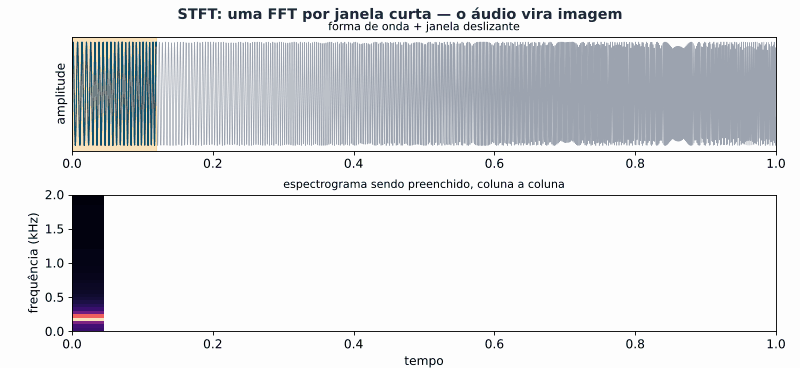

#### 📚 Fundamentos: por que "áudio vira imagem"

A FFT da Seção 4 responde *quais* frequências existem, mas não *quando*. A ideia de **Gabor (1946)** foi recortar o sinal em janelas curtas e sobrepostas e calcular uma FFT por janela. O resultado é a **STFT**:

$$X(m, k) = \sum_{n=0}^{N-1} x[n + mH]\,w[n]\,e^{-j 2\pi k n / N}$$

onde $w[n]$ é a janela (Hann, Hamming), $N$ o tamanho da FFT e $H$ o *hop* (passo entre janelas). O módulo $|X(m,k)|$ é uma matriz: linha = frequência, coluna = tempo. **É uma imagem** — e por isso toda a maquinaria de CNN desenvolvida para visão passou a valer para áudio.

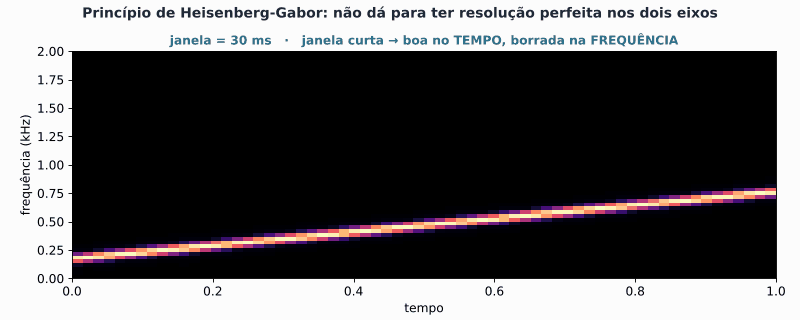

#### 📚 Fundamentos: o trade-off de Heisenberg-Gabor

Não é possível ter resolução perfeita no tempo **e** na frequência ao mesmo tempo. Vale a desigualdade

$$\Delta t \cdot \Delta f \ge \frac{1}{4\pi}$$

que é a mesma forma do princípio da incerteza de Heisenberg, aqui aplicada a sinais. Na prática:

- **janela curta** (ex.: 10 ms) → você localiza bem *quando* algo acontece, mas as frequências ficam borradas;
- **janela longa** (ex.: 100 ms) → você separa bem frequências próximas, mas perde a noção de *quando*.

Para fala, o padrão da indústria é um meio-termo: janela de **25 ms** com *hop* de **10 ms**. É o mesmo setup que o Whisper e quase todo ASR usam, e é o que usamos nas células de mel-spec a seguir.

In [ ]:
# Sinal didatico: chirp linear, frequencia varia de 200 Hz ate 4000 Hz em 3 segundos.
# Esse sinal e perfeito para mostrar visualmente como a STFT captura variacao no tempo.

duracao_chirp = 3.0
sr = 16000
t_chirp = np.linspace(0, duracao_chirp, int(sr * duracao_chirp), endpoint=False)
chirp = signal.chirp(t_chirp, f0=200, f1=4000, t1=duracao_chirp, method="linear")

print(f"Chirp gerado: {chirp.shape} amostras")
display(Audio(chirp, rate=sr))

In [ ]:
# STFT do chirp. Esperamos uma diagonal de baixo-esquerda para cima-direita,
# porque a frequencia esta subindo linearmente com o tempo.

# n_fft = 1024 amostras por janela = 64 ms a 16 kHz
# hop_length = 256 amostras = 16 ms entre janelas (sobreposicao de 75 por cento)
# Esses valores sao tipicos. Janelas menores resolvem melhor no tempo,
# maiores resolvem melhor na frequencia. E o trade-off de Heisenberg-Gabor.
S = librosa.stft(chirp, n_fft=1024, hop_length=256)
S_mag = np.abs(S)

plt.figure()
librosa.display.specshow(S_mag, sr=sr, hop_length=256,
                         x_axis="time", y_axis="linear", cmap="magma")
plt.colorbar(label="magnitude")
plt.title("Espectrograma linear de um chirp 200 Hz a 4000 Hz")
plt.show()

In [ ]:
# Mesmo audio, agora em decibeis (escala logaritmica). A audicao humana e logaritmica,
# entao ver o espectrograma em dB e mais proximo do que o ouvido percebe.
# Pequenas variacoes de energia ficam visiveis.

S_db = librosa.amplitude_to_db(S_mag, ref=np.max)

plt.figure()
librosa.display.specshow(S_db, sr=sr, hop_length=256,
                         x_axis="time", y_axis="linear", cmap="magma")
plt.colorbar(label="dB")
plt.title("Espectrograma do mesmo chirp, agora em dB")
plt.show()

**Por que decibeis sao importantes.** A audicao humana percebe volume de forma logaritmica. Dobrar a amplitude fisica nao e percebido como dobrar o volume. Trabalhar em dB aproxima a representacao numerica do que o ouvido humano realmente capta. Modelos de DL para fala quase sempre comecam convertendo o espectrograma para dB, porque isso da estabilidade numerica e melhor convergencia.

In [ ]:
# Mel-spectrogram. A escala Mel comprime altas frequencias e expande baixas,
# casando com a forma como a coclea humana resolve som.
# Em 1937, Stevens, Volkmann e Newman publicaram a escala Mel em A Scale for
# the Measurement of the Psychological Magnitude Pitch (JASA).
# Hoje, mel-spec com 80 bandas e padrao da industria em fala.

mel_spec = librosa.feature.melspectrogram(y=chirp, sr=sr, n_mels=80,
                                          n_fft=1024, hop_length=256)
mel_db = librosa.power_to_db(mel_spec, ref=np.max)

plt.figure()
librosa.display.specshow(mel_db, sr=sr, hop_length=256,
                         x_axis="time", y_axis="mel", cmap="magma")
plt.colorbar(label="dB")
plt.title("Mel-spectrogram do chirp com 80 bandas")
plt.show()

**Por que mel-spec virou padrao.** Tres motivos. Primeiro, casa com a percepcao auditiva humana, entao o modelo aprende representacoes que sao mais discriminativas para fala. Segundo, comprime altas frequencias, reduzindo a dimensionalidade do input sem perder informacao relevante para fala. Terceiro, ao usar pouca banda mas log-escalonada, regulariza o treinamento. Whisper, Tacotron 2, FastSpeech, Wav2Vec, todos comecam com mel-spec ou aprendem features equivalentes a partir de raw audio.

**Visao de mercado.** Mel-spec com 80 bandas, janela de 25 ms (n_fft=400 em 16 kHz), hop de 10 ms (hop_length=160), e o setup mais comum em fala. Se voce ve algum repositorio open source nessa area, ha 80 por cento de chance de encontrar exatamente esses numeros nos hyperparametros.

---
## Secao 6. Da fala humana para a maquina

Agora que entendemos o som como sinal, vamos trabalhar com fala humana real. A fala traz desafios que senoides puras nao tem. Tem variacao de pitch (entoacao), pausas, oclusivas (consoantes como /p/ e /t/), sopros, ruido de fundo.

Para gerar um arquivo controlado, vamos usar gTTS, a biblioteca que chama a API gratuita Text to Speech do Google Translate. E um TTS de mercado, treinado em milhares de horas, e nos da um audio de referencia em portugues brasileiro para os experimentos.

In [ ]:
# Geracao de fala em pt-BR via gTTS. Salva como MP3 e re-amostra para 16 kHz.
from gtts import gTTS

frase = ("Reconhecimento de fala converte áudio em texto. "
         "Síntese de voz converte texto em áudio. "
         "Os dois processos juntos formam a base dos assistentes inteligentes.")

# gTTS escreve MP3 porque a API do Google retorna MP3.
gTTS(frase, lang="pt-br").save("voz_demo.mp3")

# librosa converte para waveform mono em 16 kHz, padrao para STT moderno.
y_voz, sr_voz = librosa.load("voz_demo.mp3", sr=16000, mono=True)
sf.write("voz_demo.wav", y_voz, sr_voz)

print(f"Duracao: {len(y_voz)/sr_voz:.2f} segundos, sample rate {sr_voz} Hz")
display(Audio(y_voz, rate=sr_voz))

In [ ]:
# Visualizando waveform e mel-spec lado a lado.
fig, axes = plt.subplots(2, 1, figsize=(11, 6))

# Waveform
axes[0].plot(np.arange(len(y_voz)) / sr_voz, y_voz, linewidth=0.5)
axes[0].set_xlabel("tempo em segundos")
axes[0].set_ylabel("amplitude")
axes[0].set_title("Waveform da fala em pt-BR")

# Mel-spectrogram em dB
mel_voz = librosa.feature.melspectrogram(y=y_voz, sr=sr_voz, n_mels=80,
                                         n_fft=400, hop_length=160)
mel_voz_db = librosa.power_to_db(mel_voz, ref=np.max)
librosa.display.specshow(mel_voz_db, sr=sr_voz, hop_length=160,
                         x_axis="time", y_axis="mel", ax=axes[1], cmap="magma")
axes[1].set_title("Mel-spectrogram, 80 bandas, janela 25 ms, hop 10 ms")

plt.tight_layout()
plt.show()

**Davis e Mermelstein 1980, a invencao dos MFCCs.** Em julho de 1980, Steven B. Davis e Paul Mermelstein publicaram no IEEE Transactions on Acoustics, Speech, and Signal Processing o paper *Comparison of parametric representations for monosyllabic word recognition in continuously spoken sentences*. Eles propuseram aplicar a Transformada Cosseno Discreta (DCT) sobre o mel-spectrogram em log, gerando coeficientes chamados *Mel-Frequency Cepstral Coefficients* (MFCC). A motivacao era pratica: a DCT decorrelaciona as bandas Mel, gerando features compactas e ortogonais que funcionam bem com classificadores classicos como GMM (Gaussian Mixture Model) e HMM (Hidden Markov Model). Os MFCCs foram a feature padrao em reconhecimento de fala por quarenta anos. Ainda hoje aparecem em sistemas embarcados, modelos leves e em tarefas como detecao de palavra-chave (wake-word).

In [ ]:
# MFCC: features classicas que ainda sao baseline em muitos sistemas.
# 13 coeficientes e o numero classico, vem do paper de Davis e Mermelstein.

mfcc = librosa.feature.mfcc(y=y_voz, sr=sr_voz, n_mfcc=13,
                            n_fft=400, hop_length=160)
print(f"Shape dos MFCCs: {mfcc.shape}, ou seja {mfcc.shape[0]} coeficientes por janela "
      f"e {mfcc.shape[1]} janelas de 10 ms cada")

plt.figure()
librosa.display.specshow(mfcc, sr=sr_voz, hop_length=160,
                         x_axis="time", cmap="coolwarm")
plt.colorbar()
plt.ylabel("indice MFCC")
plt.title("13 coeficientes MFCC ao longo do tempo")
plt.show()

### Quando usar MFCC, Mel-spec ou raw audio em 2025

| Feature | Quando usar | Por que |
|---|---|---|
| MFCC | Pouca data, modelos simples (SVM, RandomForest), classificacao de comandos curtos | Compactos, ortogonais, faceis de classificar com modelos rasos |
| Mel-spec | Padrao da industria para CNN, RNN, Transformer em STT e TTS | Mantem estrutura espectral rica, compativel com vision-style pre-training |
| Raw waveform | Modelos muito grandes com muito dado (Wav2Vec 2.0, HuBERT, Whisper) | A rede aprende as features sozinha, melhor desempenho se houver escala |

O *raw audio* venceu o cenario porque a partir de 2020 ficou claro que, com escala suficiente de dados, a propria rede aprende representacoes melhores do que qualquer feature engineered manualmente. Mas em projetos com pouco dado, MFCC e mel-spec continuam imbativeis em custo-beneficio.

---
## Secao 7. Sintese de voz, do Voder ao WaveNet

### 7.1 A pre-historia da sintese

A primeira maquina capaz de produzir fala humana inteligivel foi o **Voder**, demonstrado por Homer Dudley em outubro de 1939 na Feira Mundial de Nova York. Era um aparelho operado por uma teclista treinada que combinava manualmente filtros eletronicos para produzir vogais e consoantes. O Voder nao era automatico, mas provou que fala humana podia sair de circuitos eletricos.

Quarenta anos depois, em 1980, Dennis Klatt, do MIT, publicou *Software for a cascade-parallel formant synthesizer* (JASA 67, 971-995). Seu sintetizador por formantes gerou a familia DECtalk, voz icone dos anos 1980, usada por Stephen Hawking nos seus comunicadores ate o fim da vida. O timbre robotico que o publico associa a sintese veio dali.

Nos anos 1990 surgiu a sintese **concatenativa**, que monta a frase juntando pedacos de audio gravados de uma pessoa real. Alan Black, Paul Taylor e Richard Caley desenvolveram o FestVox e o Festival na Universidade de Edinburgh, base de quase todo TTS comercial dos anos 1990 ate 2010. Apple usou variantes disso ate o iPhone 4S.

Nos anos 2000, a sintese parametrica baseada em HMM (Tokuda et al., sistema HTS, 2007) viabilizou TTS embarcado. O modelo era pequeno o suficiente para caber em GPS automotivo.

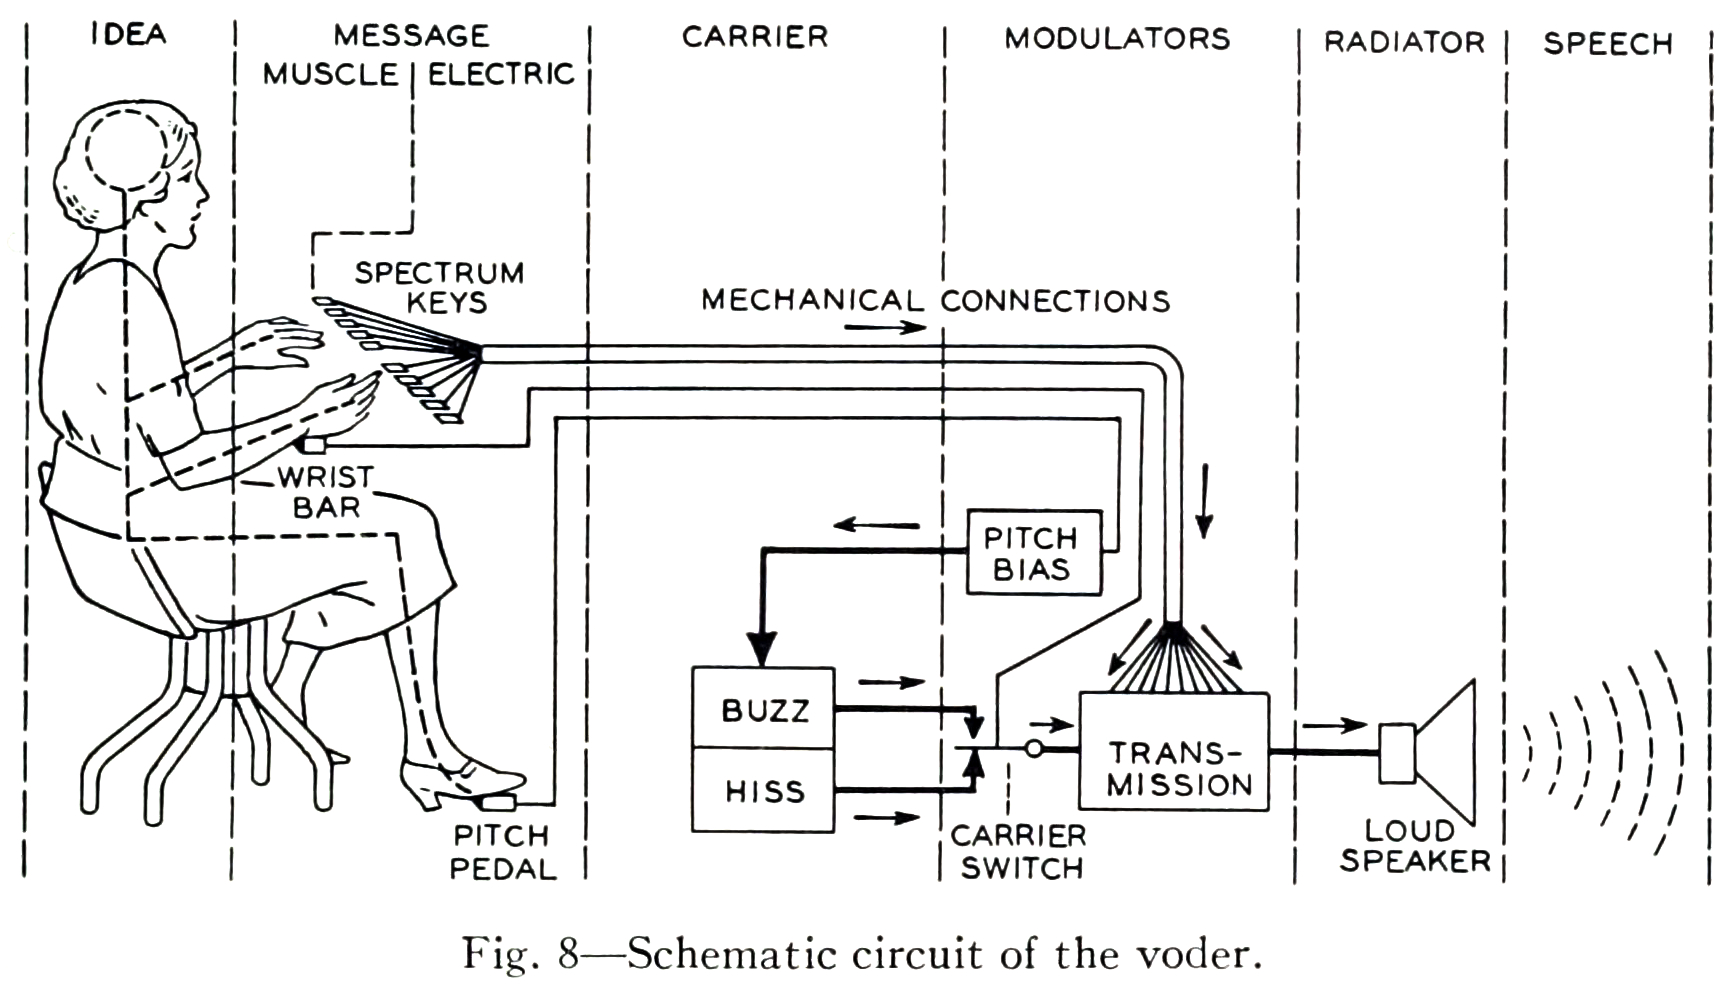

### 7.2 A virada neural: WaveNet 2016

Em setembro de 2016, Aaron van den Oord e nove coautores do Google DeepMind publicaram o paper *WaveNet: A Generative Model for Raw Audio* (arXiv:1609.03499). Foi a primeira arquitetura neural a modelar diretamente a forma de onda do audio, amostra por amostra, em 16 bits e 16 kHz. A rede usava convolucoes causais dilatadas, uma engenhoca matematica que aumenta o campo receptivo da CNN exponencialmente sem aumentar o numero de parametros na mesma proporcao.

O teste central foi avaliacao subjetiva por humanos. WaveNet atingiu **Mean Opinion Score de 4,21** em uma escala de 1 a 5 para ingles americano, contra 4,55 da gravacao humana natural. A sintese concatenativa comercial do Google da epoca pontuava 3,86. Era um salto qualitativo notavel, e provou que redes generativas podiam atingir naturalidade humana.

O problema do WaveNet original era custo. Gerar um segundo de audio levava varios minutos em GPU, porque o modelo e autoregressivo (cada amostra depende da anterior). Resolver isso virou tarefa de pesquisa e gerou *Parallel WaveNet* (2017) e WaveGlow (2018).

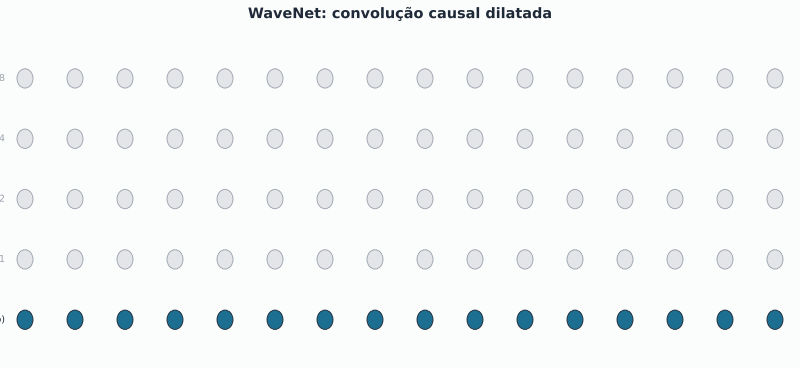

#### 📚 Fundamentos: convolução causal dilatada

O WaveNet modela o áudio amostra a amostra: $p(x) = \prod_t p(x_t \mid x_1, \dots, x_{t-1})$. Para prever uma amostra ele só pode olhar o **passado** (daí *causal*), e precisa de um contexto longo — a 16 kHz, 1 segundo são 16.000 amostras.

Uma CNN causal comum precisaria de milhares de camadas para enxergar tão longe. A solução são as **dilatações**: cada camada pula um número crescente de amostras ($1, 2, 4, 8, \dots$), de modo que o **campo receptivo cresce como $2^{\text{camadas}}$**, não linearmente. A animação mostra isso: com 4 camadas dilatadas, um único neurônio no topo já "enxerga" 16 amostras.

$$\text{campo receptivo} = (\text{tamanho do kernel} - 1)\sum_{i} d_i + 1$$

É a mesma ideia que depois apareceu no TCN (*Temporal Convolutional Network*) e em partes de vocoders modernos. O custo do WaveNet original era ser **autoregressivo** na geração (uma amostra por vez), o que motivou o Parallel WaveNet e, mais tarde, vocoders GAN como o HiFi-GAN.

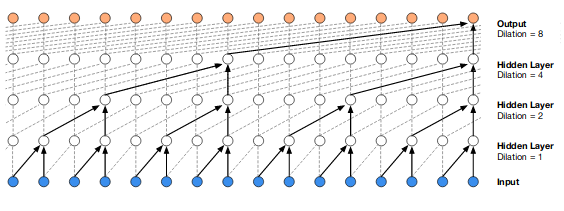

### 7.3 Tacotron 2017 e a separacao de tarefas

Em marco de 2017, Yuxuan Wang e treze coautores do Google publicaram *Tacotron: Towards End-to-End Speech Synthesis* (arXiv:1703.10135). A inovacao foi separar o problema em duas etapas. Primeiro, um modelo Seq2Seq com atencao traduz texto em mel-spectrogram. Depois, um vocoder neural converte mel-spec em waveform.

A versao Tacotron 2 (Shen et al., ICASSP 2018) conectou o gerador de mel-spec ao WaveNet como vocoder. O Mean Opinion Score atingiu 4,53, estatisticamente indistinguivel de gravacao humana profissional. Esse pipeline texto, mel-spec, waveform virou o padrao da industria. ElevenLabs, Coqui XTTS, Resemble e quase todos os TTS open source de 2024 seguem essa estrutura, com vocoders mais rapidos (HiFi-GAN, BigVGAN).

### 7.4 TTS na pratica: gTTS

gTTS nao e um modelo no seu computador, e um wrapper Python para a API gratuita do Google Translate. O audio e gerado nos servidores do Google, usando provavelmente uma variante interna do Tacotron com WaveNet ou HiFi-GAN. Para producao real voce avaliaria Google Cloud TTS oficial, Azure Speech, Amazon Polly, ElevenLabs ou Coqui TTS open source. Mas para experimentos didaticos, gTTS resolve.

In [ ]:
# TTS basico em portugues. Salva como MP3.
gTTS("Bom dia, esse é o nosso teste de síntese de voz em portugues brasileiro.",
     lang="pt-br").save("tts_pt.mp3")
display(Audio("tts_pt.mp3"))

In [ ]:
# Multi-idioma. A mesma frase, traduzida, sintetizada em sete idiomas.
# Note as diferencas de prosodia (entoacao) entre linguas tonais e nao tonais.

idiomas = {
    "Portugues brasileiro": ("pt-br", "Sintese de voz com aprendizado profundo"),
    "Ingles":               ("en",    "Speech synthesis with deep learning"),
    "Espanhol":             ("es",    "Sintesis de voz con aprendizaje profundo"),
    "Frances":              ("fr",    "Synthese vocale avec apprentissage profond"),
    "Italiano":             ("it",    "Sintesi vocale con apprendimento profondo"),
    "Alemao":               ("de",    "Sprachsynthese mit Deep Learning"),
    "Japones":              ("ja",    "ディープラーニングによる音声合成"),
}

for nome, (codigo, texto) in idiomas.items():
    arquivo = f"tts_{codigo}.mp3"
    gTTS(texto, lang=codigo).save(arquivo)
    print(f"{nome}: {texto}")
    display(Audio(arquivo))

In [ ]:
# Comparando velocidade normal e velocidade reduzida (slow=True).
# Util para casos de acessibilidade, ensino de idiomas e leitura para idosos.

texto_velocidade = "A inteligencia artificial transforma a forma como interagimos com maquinas."

gTTS(texto_velocidade, lang="pt-br", slow=False).save("normal.mp3")
gTTS(texto_velocidade, lang="pt-br", slow=True).save("lento.mp3")

print("Velocidade normal:")
display(Audio("normal.mp3"))
print("Velocidade reduzida:")
display(Audio("lento.mp3"))

---
## Secao 8. Reconhecimento de fala, da Audrey ao Whisper

### 8.1 Audrey, 1952

Em 1952, K. H. Davis, R. Biddulph e S. Balashek publicaram no Journal of the Acoustical Society of America o paper *Automatic Recognition of Spoken Digits*. O sistema, apelidado de Audrey pelos engenheiros da Bell Labs, era inteiramente analogico. Reconhecia digitos de zero a nove ditos por **um unico falante**, e atingia acuracia reportada de 97 a 99 por cento naquele setup restrito. Audrey usava analise de formantes em circuito eletrico, sem nenhum computador digital envolvido. Foi a primeira demonstracao tecnica de reconhecimento de fala que funcionou.

### 8.2 DARPA SUR e o nascimento do beam search, 1971

Em 1971, a DARPA lancou o programa **Speech Understanding Research** (SUR), com orcamento de quinze milhoes de dolares ao longo de cinco anos. O programa foi liderado por Raj Reddy em Carnegie Mellon University. O sistema Harpy, resultado do SUR, reconhecia **1011 palavras**, com vocabulario fixo e gramatica restrita. Introduziu o conceito de busca em rede de estados (beam search), que segue sendo central no decodificador de qualquer ASR moderno, do Kaldi ao Whisper.

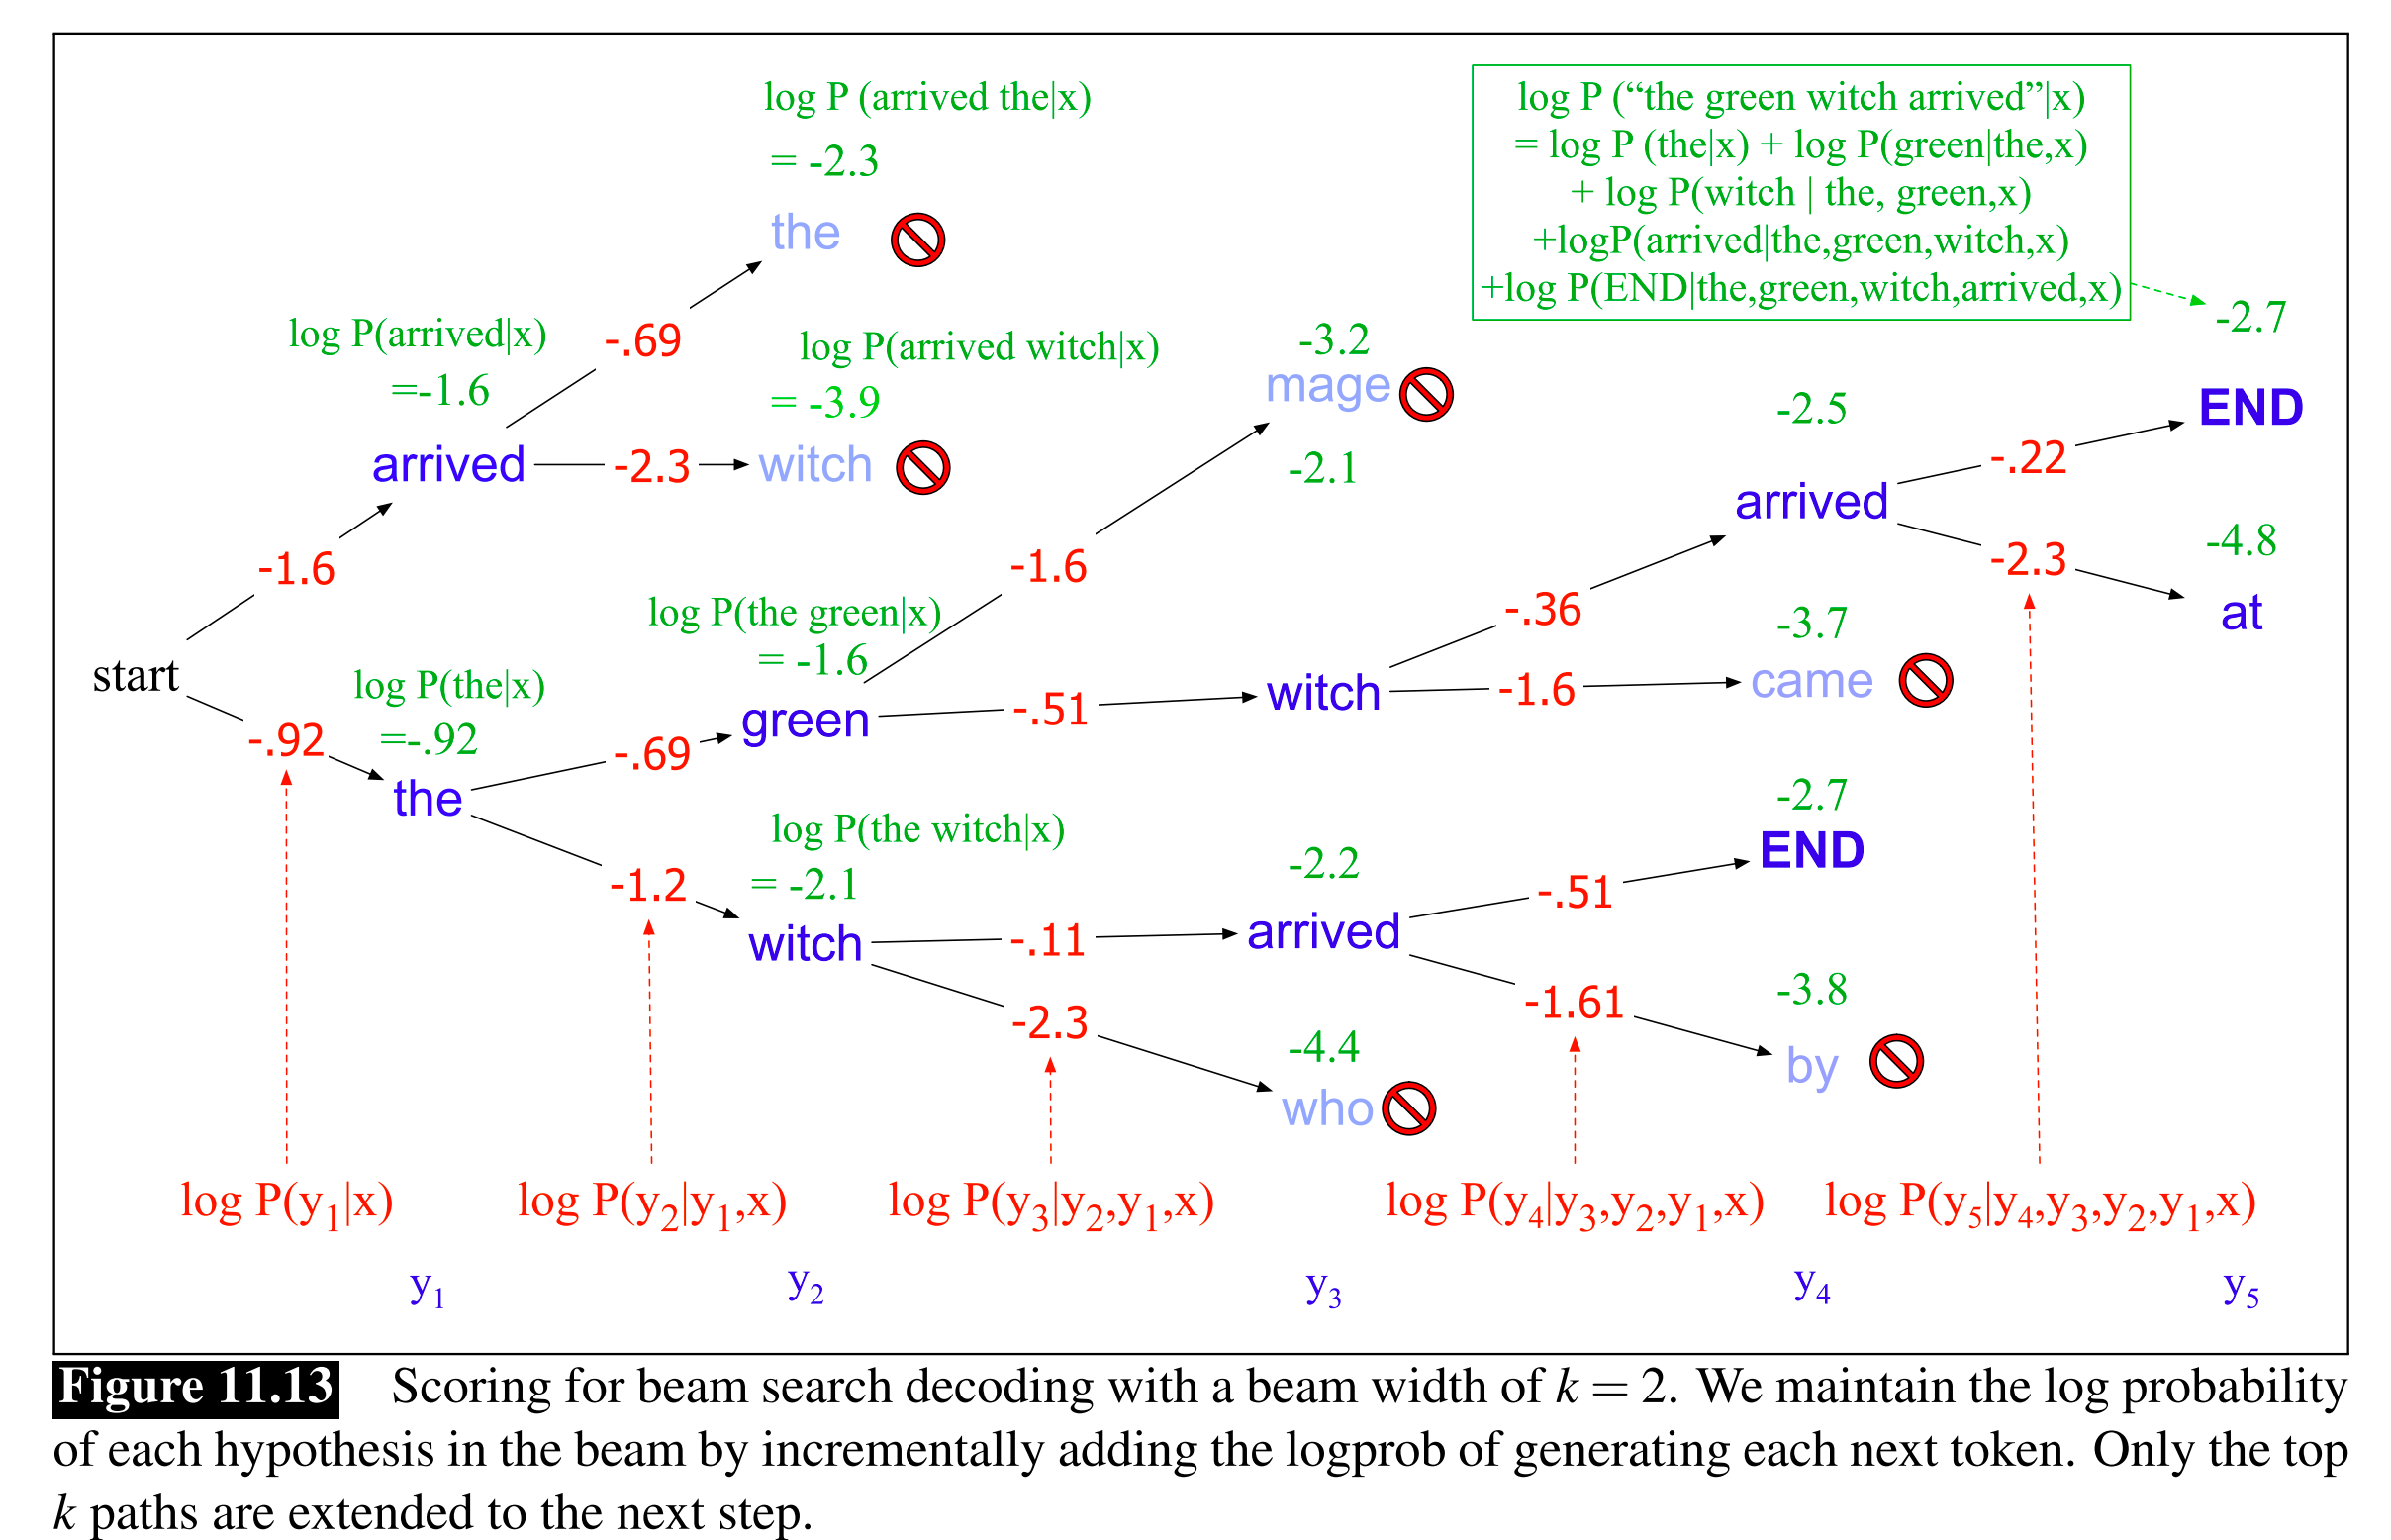

### 8.3 A era HMM-GMM, 1989

Em fevereiro de 1989, Lawrence Rabiner publicou no Proceedings of the IEEE o tutorial *A Tutorial on Hidden Markov Models and Selected Applications in Speech Recognition* (volume 77, paginas 257 a 286). Esse texto formalizou a era HMM e dominou o estado da arte ate cerca de 2011. A arquitetura padrao era em pipeline: features MFCC (Davis e Mermelstein 1980) alimentam um modelo acustico GMM-HMM, que conversa com um modelo de linguagem n-grama, e tudo isso e amarrado por um decodificador WFST. O sistema Kaldi (Povey et al., 2011) ainda implementa essa pilha e e usado em industrias que precisam de modelo customizavel e auditavel.

### 8.4 O salto deep learning, 2012-2015

Em outubro de 2012, **Geoffrey Hinton, Li Deng, Dong Yu, George Dahl** e mais sete coautores publicaram na IEEE Signal Processing Magazine o paper *Deep Neural Networks for Acoustic Modeling in Speech Recognition*. O trabalho mostrou que substituir as GMMs por DNNs reduzia o Word Error Rate em 10 a 30 por cento em quatro benchmarks da industria simultaneamente (Bing Voice Search, Switchboard, Google Voice Search e YouTube). Foi a transicao oficial da era HMM-GMM para a era do deep learning em fala.

Em dezembro de 2014, **Awni Hannun** e mais dez coautores da Baidu Research Silicon Valley publicaram *Deep Speech: Scaling up end-to-end speech recognition* (arXiv:1412.5567). A arquitetura abandonava o pipeline GMM-HMM-WFST por uma RNN treinada de ponta a ponta com a perda **CTC** (Connectionist Temporal Classification, Graves et al. 2006). O paper reportou Word Error Rate de 16 por cento em Switchboard Hub5 00 e 7,1 por cento em audio limpo do Wall Street Journal, com robustez a ruido superior a sistemas comerciais da epoca. A versao open source da Mozilla, batizada DeepSpeech, virou referencia academica nos anos seguintes.

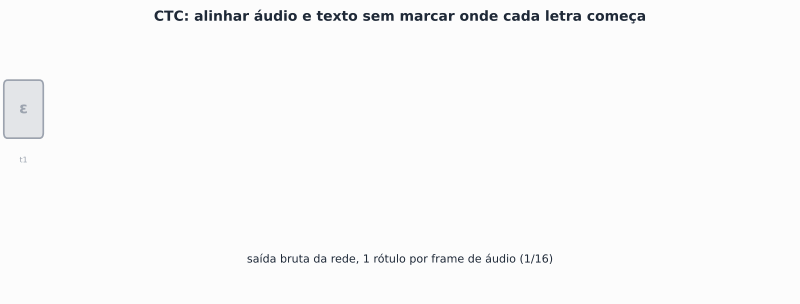

#### 📚 Fundamentos: CTC, o truque que tornou o STT ponta a ponta

O grande obstáculo do reconhecimento de fala sempre foi o **alinhamento**: o áudio tem centenas de frames por segundo, o texto tem poucas letras, e ninguém marca à mão onde cada letra começa. O **CTC** (*Connectionist Temporal Classification*, **Graves et al., 2006**) resolveu isso e viabilizou o Deep Speech.

A rede emite um rótulo por frame, incluindo um símbolo especial **blank** ($\varepsilon$). Para obter o texto final aplicam-se duas regras (veja a animação):

1. **colapsar repetições consecutivas**: `CC → C`, `OO → O`;
2. **remover os blanks** $\varepsilon$.

Assim `_ _ C C _ A A _ _ T T _ _ O O _` vira `CATO`. Como *muitos* alinhamentos de frames geram a mesma palavra, a perda CTC **soma a probabilidade de todos eles** com programação dinâmica (um *forward-backward* parecido com o de HMM):

$$p(\text{texto} \mid \text{áudio}) = \sum_{\text{alinhamentos válidos}} \prod_t p(\text{rótulo}_t \mid \text{frame}_t)$$

O blank é o que permite repetir letras de verdade (`BOLA` tem um só `L`, mas `BELLE` precisa de dois — o blank entre eles evita que colapsem). Whisper, por ser um Transformer encoder-decoder, **não** usa CTC; mas wav2vec 2.0 e a maioria dos modelos *streaming* ainda usam.

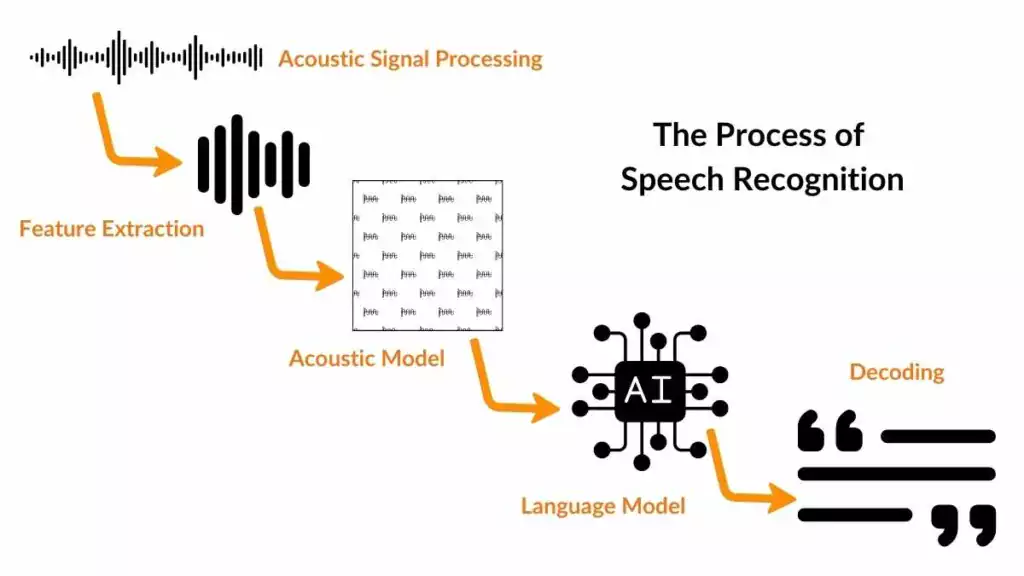

### 8.5 wav2vec 2.0 e Whisper, 2020-2022

Em junho de 2020, **Alexei Baevski, Henry Zhou, Abdelrahman Mohamed e Michael Auli**, da Meta AI, publicaram no NeurIPS *wav2vec 2.0: A Framework for Self-Supervised Learning of Speech Representations*. A ideia central foi pre-treinar um Transformer sobre audio cru, mascarando segmentos no dominio temporal e prevendo representacoes quantizadas. Com fine-tune em apenas 10 minutos de fala rotulada, o modelo BASE atingiu Word Error Rate de 5,7 em test-clean do LibriSpeech, comparavel a sistemas treinados em centenas de horas etiquetadas. Foi o paper que mostrou que pre-treino auto-supervisionado iria dominar a area.

Em setembro de 2022, **Alec Radford** e mais sete coautores da OpenAI publicaram *Robust Speech Recognition via Large-Scale Weak Supervision* (arXiv:2212.04356). O Whisper foi treinado em 680 mil horas de audio multilingue coletadas da web, com supervisao fraca (transcricoes da propria web, sem revisao). Demonstrou robustez a ruido, sotaque, vocabulario tecnico e desempenho competitivo com modelos supervisionados sem fine-tuning adicional. As variantes vao de tiny (39 milhoes de parametros) a large-v3 (1,55 bilhao). Para fala em portugues brasileiro, base ou small ja resolvem a maior parte dos casos com WER abaixo de 10 por cento.

### 8.6 STT na pratica

Vamos comparar dois caminhos. Primeiro, SpeechRecognition + Google Web API, que e simples mas chama servidor remoto. Depois, Whisper local, que baixa o modelo e roda na sua maquina.

In [ ]:
# SpeechRecognition + Google Web API. Setup de duas linhas, sem GPU.
import speech_recognition as sr_lib

r = sr_lib.Recognizer()

with sr_lib.AudioFile("voz_demo.wav") as fonte:
    audio = r.record(fonte)

texto_google = r.recognize_google(audio, language="pt-BR")
print("Transcricao via Google Web:")
print(texto_google)

**Atencao para producao.** A `recognize_google` da biblioteca SpeechRecognition usa um endpoint nao oficial e nao documentado do Google. Funciona muito bem para testes e prototipos, mas nao tem garantia de SLA, pode quebrar sem aviso e tem cota nao publicada. Para producao, use a API oficial Google Cloud Speech-to-Text, Azure Cognitive Services, Amazon Transcribe ou um modelo local como Whisper.

In [ ]:
# Whisper local. A primeira execucao baixa o modelo (cerca de 140 MB para base).
# Em GPU leva 1 a 2 segundos. Em CPU pode demorar 10 a 20 segundos por audio curto.
import whisper

modelo_whisper = whisper.load_model("base", device=str(DEVICE))
print("Whisper base carregado")

resultado = modelo_whisper.transcribe("voz_demo.wav", language="pt", fp16=(DEVICE.type == "cuda"))
print()
print("Transcricao via Whisper base:")
print(resultado["text"])

**Observacoes praticas sobre Whisper.** O modelo `base` tem 74 milhoes de parametros e roda razoavelmente em CPU. Para qualidade superior em portugues, vale usar `small` (244 milhoes) ou `medium` (769 milhoes). Em producao com GPU, a versao `large-v3` da resultados estado da arte mas pede VRAM acima de 10 GB. Para deploy serio, considere `faster-whisper`, que e a mesma arquitetura compilada com CTranslate2 e roda 4 vezes mais rapido. Existe tambem `whisper.cpp` para CPU embarcada, e versoes em Rust e Go para servicos backend.

In [ ]:
# Whisper com timestamps por segmento. Util para legendas e busca por trecho.
resultado_ts = modelo_whisper.transcribe("voz_demo.wav", language="pt",
                                          fp16=(DEVICE.type == "cuda"), verbose=False)

print("Segmentos com timestamps:")
for seg in resultado_ts["segments"]:
    inicio, fim = seg["start"], seg["end"]
    print(f"[{inicio:5.2f}s -> {fim:5.2f}s] {seg['text']}")

### 8.7 Comparando os tamanhos do Whisper: velocidade × qualidade

O Whisper vem em vários tamanhos. Quanto maior, melhor a transcrição e mais lento. A célula abaixo mede, no mesmo áudio, o **tempo de processamento** e o **Real Time Factor (RTF)** de cada tamanho que couber na memória. Em produção, essa curva é o que decide qual modelo usar.

In [ ]:
# Comparacao de tamanhos do Whisper no MESMO audio.
# RTF (Real Time Factor) = tempo de processamento / duracao do audio. RTF < 1 = mais rapido que tempo real.
# Em CPU rode so ["tiny", "base"]. Em GPU pode incluir "small" e "medium".

import time

TAMANHOS = ["tiny", "base", "small"]   # acrescente "medium"/"large-v3" se tiver GPU com VRAM sobrando
dur_audio = len(y_voz) / sr_voz

linhas = []
for nome in TAMANHOS:
    try:
        t0 = time.time()
        m = whisper.load_model(nome, device=str(DEVICE))
        t_load = time.time() - t0

        t0 = time.time()
        txt = m.transcribe("voz_demo.wav", language="pt", fp16=(DEVICE.type == "cuda"))["text"].strip()
        t_infer = time.time() - t0

        n_params = sum(p.numel() for p in m.parameters()) / 1e6
        linhas.append((nome, n_params, t_load, t_infer, t_infer / dur_audio, txt))
        del m
    except Exception as e:
        print(f"{nome}: nao foi possivel carregar ({str(e)[:60]})")

print(f"{'modelo':8s} {'M par':>7s} {'carga':>7s} {'infer':>7s} {'RTF':>6s}  transcricao")
print("-" * 100)
for nome, par, tl, ti, rtf, txt in linhas:
    print(f"{nome:8s} {par:7.0f} {tl:6.1f}s {ti:6.1f}s {rtf:6.2f}  {txt[:48]}")

if len(linhas) >= 2:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
    nomes = [l[0] for l in linhas]
    ax1.bar(nomes, [l[1] for l in linhas], color="#1C7293")
    ax1.set_ylabel("milhoes de parametros"); ax1.set_title("Tamanho do modelo")
    ax2.bar(nomes, [l[4] for l in linhas], color="#F59E0B")
    ax2.axhline(1.0, color="#DC2626", ls="--", label="tempo real (RTF=1)")
    ax2.set_ylabel("RTF (menor = mais rapido)"); ax2.set_title("Custo de inferencia"); ax2.legend()
    plt.tight_layout(); plt.show()

**Leitura.** `tiny` e `base` servem para protótipos e rodam em CPU; `small` costuma ser o melhor custo-benefício para português; `medium`/`large-v3` ficam para quando a qualidade é crítica e há GPU. Para produção, troque `openai-whisper` por **`faster-whisper`** (mesma arquitetura compilada com CTranslate2, ~4× mais rápido e menos memória) ou **`whisper.cpp`** em CPU embarcada.

---
## Secao 9. Ruido e sua remocao com deep learning

Essa e a secao mais densa do notebook e tambem a mais subestimada nos cursos. Em projetos reais, a qualidade do reconhecimento de fala depende mais do pre-processamento de ruido do que do modelo de STT escolhido. Whisper large com audio de call center sujo tem WER pior do que Whisper base com audio limpo. Conhecer o pipeline historico de denoising e o que separa o engenheiro intermediario do senior nessa area.

### 9.1 A era Wiener, anos 1940 e 1950

A primeira abordagem rigorosa de filtragem de sinal ruidoso veio de **Norbert Wiener** em 1949, com o livro *Extrapolation, Interpolation, and Smoothing of Stationary Time Series*. O filtro Wiener assume que sinal e ruido sao processos estocasticos estacionarios com densidades espectrais conhecidas, e calcula o filtro otimo que minimiza o erro quadratico medio entre o sinal estimado e o sinal verdadeiro. Para fala, a estacionariedade nao se mantem (fala muda constantemente), mas a estrutura matematica do Wiener inspirou tudo que veio depois.

### 9.2 Boll 1979, a base do denoising classico

Em abril de 1979, **Steven F. Boll**, na epoca pesquisador da US Air Force Rome Air Development Center e professor visitante na Universidade de Utah, publicou no IEEE Transactions on Acoustics, Speech, and Signal Processing (volume 27, numero 2, paginas 113 a 120) o paper *Suppression of Acoustic Noise in Speech Using Spectral Subtraction*.

A ideia e elegante. Em qualquer gravacao de fala existem trechos de silencio entre palavras. Nesses trechos, o que sai do microfone e essencialmente ruido. Se a gente estima o espectro de magnitude do ruido nesses trechos silenciosos, podemos depois subtrair esse espectro estimado do espectro do audio inteiro. O que sobra deveria ser predominantemente fala.

Matematicamente, em cada janela de tempo *m*, se *Y(k,m)* e o espectro observado, *S(k,m)* o espectro da fala e *N(k)* o espectro estimado do ruido, entao:

$$ |\hat{S}(k,m)| = \max(|Y(k,m)| - |N(k)|, 0) $$

A fase original do sinal observado e mantida (a percepcao humana e relativamente insensivel a fase em ruido moderado). O sinal reconstruido sai pela ISTFT Inverse Short-Time Fourier Transform.

O teste no paper original foi feito em fala militar gravada em ambientes ruidosos, com avaliacao subjetiva por ouvintes treinados. Boll reportou melhoria de inteligibilidade em SNRs de 5 a 15 dB. A limitacao conhecida e o **ruido musical**, tons curtos espurios que aparecem porque a subtracao zera componentes individuais que estavam apenas marginalmente acima do ruido estimado.

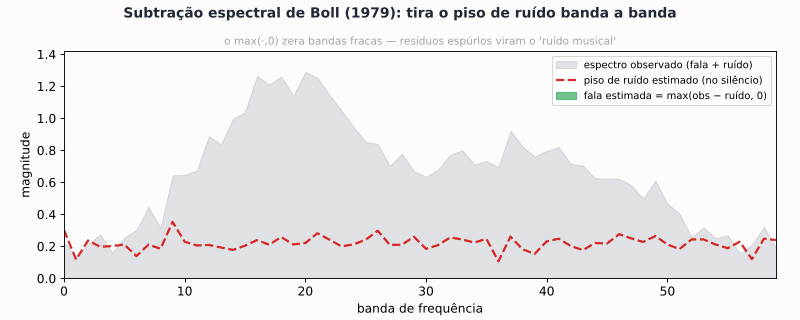

In [ ]:
# Implementacao didatica do Boll 1979. Em producao voce usaria noisereduce ou
# um modelo neural, mas implementar a partir do zero faz a logica ficar clara.

def boll_spectral_subtraction(y, sr, n_fft=512, hop_length=128,
                              n_frames_ruido=10, alpha=1.5):
    '''Subtracao espectral classica de Boll 1979.

    Parametros:
      y: sinal de entrada, mono
      sr: sample rate
      n_fft: tamanho da FFT
      hop_length: passo entre janelas
      n_frames_ruido: quantas janelas do inicio usar para estimar ruido
                      (assume que o inicio nao tem fala)
      alpha: fator de subtracao. alpha=1 e subtracao pura.
             alpha>1 superestima ruido, suprime mais mas pode mutilar fala.
    '''
    # STFT do sinal observado
    S_obs = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)
    magnitude = np.abs(S_obs)
    fase = np.angle(S_obs)

    # Estima o espectro do ruido a partir das primeiras janelas
    ruido_estimado = np.mean(magnitude[:, :n_frames_ruido], axis=1, keepdims=True)

    # Subtracao com piso em zero. O max evita valores negativos sem sentido fisico.
    magnitude_limpa = np.maximum(magnitude - alpha * ruido_estimado, 0.0)

    # ISTFT: reconstroi com a fase original
    S_limpo = magnitude_limpa * np.exp(1j * fase)
    y_limpo = librosa.istft(S_limpo, hop_length=hop_length)

    return y_limpo

# Demo: adiciona ruido branco a uma fala limpa, depois aplica Boll
y_limpa = y_voz.copy()
# 0, 0.02, len(y_limpa)
ruido_branco = np.random.normal(0, 0.09, len(y_limpa))
y_ruidosa = y_limpa + ruido_branco

y_boll = boll_spectral_subtraction(y_ruidosa, sr_voz)

# Tres versoes lado a lado
print("Original limpa:")
display(Audio(y_limpa, rate=sr_voz))
print("Com ruido aditivo:")
display(Audio(y_ruidosa, rate=sr_voz))
print("Apos Boll 1979:")
display(Audio(y_boll, rate=sr_voz))

In [ ]:
# Visualizando o efeito do Boll no espectrograma.
fig, axes = plt.subplots(3, 1, figsize=(11, 8))

for ax, (sinal, titulo) in zip(axes, [
    (y_limpa, "Original limpa"),
    (y_ruidosa, "Com ruido aditivo"),
    (y_boll, "Apos subtracao espectral de Boll 1979"),
]):
    mel = librosa.feature.melspectrogram(y=sinal, sr=sr_voz, n_mels=80,
                                         n_fft=400, hop_length=160)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    librosa.display.specshow(mel_db, sr=sr_voz, hop_length=160,
                              x_axis="time", y_axis="mel", ax=ax, cmap="magma")
    ax.set_title(titulo)

plt.tight_layout()
plt.show()

### 9.3 Ephraim e Malah 1984, o refinamento bayesiano

Em dezembro de 1984, **Yariv Ephraim e David Malah**, ambos no Technion em Haifa, publicaram no IEEE TASSP (volume 32, numero 6, paginas 1109 a 1121) o paper *Speech Enhancement Using a Minimum-Mean Square Error Short-Time Spectral Amplitude Estimator*. O estimador MMSE-STSA e bayesiano. Em vez de subtrair magnitudes diretamente, modela a amplitude espectral instantanea como variavel aleatoria com priori conhecida, e calcula a estimativa que minimiza o erro quadratico esperado.

O resultado pratico e que MMSE-STSA produz menos ruido musical do que Boll. O follow-up de 1985 dos mesmos autores estendeu para *Log-Spectral Amplitude*. Ainda hoje, MMSE-STSA serve de baseline analitico que sistemas de deep learning para denoising precisam superar para serem publicaveis.

### 9.4 RNNoise, 2018: o primeiro hibrido DSP-DL em producao

Em setembro de 2017, **Jean-Marc Valin**, na epoca pesquisador da Mozilla Corporation e do consorcio Xiph.Org, publicou *A Hybrid DSP/Deep Learning Approach to Real-Time Full-Band Speech Enhancement* (arXiv:1709.08243). O paper foi apresentado oficialmente em agosto de 2018 no IEEE Multimedia Signal Processing Workshop.

A arquitetura e brilhante na sua sobriedade. RNNoise nao tenta substituir o pipeline classico de DSP por uma rede neural gigante. Pelo contrario. Ele mantem o pipeline classico (analise espectral, divisao em bandas de frequencia perceptuais) e usa uma rede GRU pequena (cerca de 215 mil pesos) so para estimar os **ganhos por banda**. Esses ganhos sao aplicados ao espectro classicamente.

O sistema processa quadros de 10 ms em 48 kHz, extrai 42 features (envelope de 22 bandas Bark mais derivadas temporais), e a GRU emite 22 ganhos. Treinou com 6 horas de fala limpa do dataset McGill e centenas de horas de ruidos do dataset Noise92, AudioSet e gravacoes proprias.

O resultado e um denoiser que **roda em tempo real em CPU de Raspberry Pi 3**. RNNoise virou base para o plugin do werman usado em Discord, OBS, Audacity. Foi tambem a porta de entrada para a famosa onda de plugins de remocao de ruido baseados em DL que veio depois.

### 9.5 A onda comercial: Krisp, NVidia, DNS Challenge

A partir de 2018, a Microsoft criou o **Deep Noise Suppression Challenge** (Reddy et al., publicado anualmente em Interspeech), que padronizou benchmarks para a area. As empresas seguiram. **Krisp**, fundada em 2017 na California, oferece denoise por DL embarcado em Zoom, Microsoft Teams, Discord. **NVidia Broadcast** (2020) integra um denoiser DL no driver da placa de video, processando em tempo real com latencia abaixo de 10 ms. **Adobe Enhance Speech** (2023) aplica modelos generativos para nao so remover ruido mas reconstruir partes faltantes da fala.

Em 2020, **Alexandre Defossez, Gabriel Synnaeve e Yossi Adi**, da Meta AI, publicaram em Interspeech *Real Time Speech Enhancement in the Waveform Domain*, com o modelo Demucs adaptado para denoising. Demucs trabalha diretamente em waveform, sem passar por espectrograma, e atinge qualidade superior em metricas objetivas e subjetivas. Em 2023 e 2024, modelos como **DeepFilterNet** (Schroter et al.) refinaram o estado da arte com arquiteturas mais eficientes.

### 9.6 Hands on: noisereduce, sucessor pratico do Boll

A biblioteca `noisereduce`, mantida por Tim Sainburg, implementa *spectral gating* nao estacionario, que e essencialmente uma variante moderna do Boll com estimativa de ruido continua. Nao e baseada em DL puro, mas e o que vou recomendar como solucao plug and play para projetos onde voce nao precisa do estado da arte e quer codigo simples.

In [ ]:
sr_voz

In [ ]:
# noisereduce como solucao pronta. Compare com a versao do Boll que implementamos.
import noisereduce as nr

# A funcao reduce_noise estima o ruido automaticamente ou via amostra de referencia.
# prop_decrease entre 0 e 1 controla quanto do ruido remover. 0.8 e um bom default.
y_nr = nr.reduce_noise(y=y_ruidosa, sr=sr_voz, prop_decrease=0.8)

print("Comparativo de tres abordagens de denoising")
print()
print("Sem nenhum tratamento (audio ruidoso):")
display(Audio(y_ruidosa, rate=sr_voz))
print("Boll 1979, implementacao didatica:")
display(Audio(y_boll, rate=sr_voz))
print("noisereduce, spectral gating moderno:")
display(Audio(y_nr, rate=sr_voz))

In [ ]:
# O teste que importa: o denoising melhora o STT?
# Vamos medir Word Error Rate em cada versao com Whisper base.

from jiwer import wer

# A frase original que sintetizamos no inicio
referencia = ("Reconhecimento de fala converte audio em texto. "
              "Sintese de voz converte texto em audio. "
              "Os dois processos juntos formam a base dos assistentes inteligentes.")

# Salvamos cada versao para o Whisper transcrever
sf.write("ruidoso.wav", y_ruidosa, sr_voz)
sf.write("boll.wav", y_boll, sr_voz)
sf.write("nr.wav", y_nr, sr_voz)

resultados_wer = {}
for nome, arquivo in [("Sem denoise", "ruidoso.wav"),
                       ("Apos Boll 1979", "boll.wav"),
                       ("Apos noisereduce", "nr.wav")]:
    transcricao = modelo_whisper.transcribe(arquivo, language="pt", fp16=(DEVICE.type == "cuda"))["text"]
    erro = wer(referencia.lower(), transcricao.lower().strip())
    resultados_wer[nome] = (erro, transcricao)

print(f"{'Versao':25s} {'WER':>8s}   Transcricao")
print("-" * 90)
for nome, (erro, txt) in resultados_wer.items():
    print(f"{nome:25s} {erro:8.3f}   {txt[:60]}")

**Leitura do experimento.** Em audios sinteticos como esse, com ruido branco controlado, qualquer denoise melhora o WER. Em audios reais, o ganho depende muito do tipo de ruido. Ruido estacionario (ar condicionado, ventilador) e removido facilmente. Ruido nao estacionario (musica, voz de outra pessoa, batidas) e bem mais dificil. Para call center serio em 2025, a recomendacao da industria e empilhar duas camadas. Primeiro um denoise leve (RNNoise ou DeepFilterNet) para limpar o sinal. Depois um STT robusto (Whisper, Wav2Vec). Cada camada tem job especifico e responsabilidade clara, o que tambem facilita debug em producao.

### 9.7 VAD: separar fala de silêncio antes de transcrever

Antes de mandar áudio para o STT, pipelines de produção aplicam **VAD** (*Voice Activity Detection*): detectar quais trechos têm fala e descartar o silêncio. Isso corta custo (o Whisper não gasta tempo com silêncio), evita alucinação do modelo em trechos vazios e é a base da segmentação por palavra do caso integrador da Seção 13.

O **Silero VAD** é o padrão prático hoje: um modelo minúsculo (~1 MB), roda em CPU em tempo real, e é usado dentro de incontáveis projetos de ASR. A célula abaixo recorta a fala de um áudio com silêncios e mede quanto foi descartado.

In [ ]:
# VAD com Silero. Modelo minusculo (~1 MB), roda em CPU.
# pip install silero-vad   (ja incluido no setup)
import numpy as np

# Monta um audio com silencios no inicio, meio e fim para o VAD ter o que recortar
silencio = np.zeros(int(0.8 * sr_voz), dtype=np.float32)
y_com_silencio = np.concatenate([silencio, y_voz, silencio, y_voz[: len(y_voz)//2], silencio]).astype(np.float32)
sf.write("com_silencio.wav", y_com_silencio, sr_voz)

try:
    from silero_vad import load_silero_vad, get_speech_timestamps

    modelo_vad = load_silero_vad()
    # get_speech_timestamps aceita um tensor/np 1-D float32 em 16 kHz
    fala_ts = get_speech_timestamps(y_com_silencio, modelo_vad,
                                    sampling_rate=sr_voz, return_seconds=True)

    print("Trechos com fala detectados:")
    dur_fala = 0.0
    for seg in fala_ts:
        print(f"  [{seg['start']:5.2f}s -> {seg['end']:5.2f}s]")
        dur_fala += seg["end"] - seg["start"]

    dur_total = len(y_com_silencio) / sr_voz
    print(f"\nDuracao total: {dur_total:.2f}s | com fala: {dur_fala:.2f}s | "
          f"silencio descartado: {(1 - dur_fala/dur_total)*100:.0f}%")

    # Visualiza as regioes de fala sobre a waveform
    plt.figure(figsize=(11, 3))
    tempo = np.arange(len(y_com_silencio)) / sr_voz
    plt.plot(tempo, y_com_silencio, color="#9CA3AF", lw=0.5)
    for seg in fala_ts:
        plt.axvspan(seg["start"], seg["end"], color="#16A34A", alpha=0.25)
    plt.title("Silero VAD: regioes verdes contem fala, o resto e descartado")
    plt.xlabel("tempo (s)"); plt.ylabel("amplitude"); plt.show()
except Exception as e:
    print(f"Silero VAD indisponivel ({str(e)[:80]}). Instale com: pip install silero-vad")

---
## Secao 10. Aumento de dados em audio

Quando o problema e o oposto, treinar um modelo robusto com pouca data, a tecnica e *data augmentation*. Em vez de remover ruido do audio, voce **adiciona** ruido controlado durante o treinamento, para forcar o modelo a ser invariante a essas perturbacoes. Tres tecnicas classicas e uma moderna.

In [ ]:
# Adicao de ruido controlado por SNR.
# SNR (Signal to Noise Ratio) e a razao em dB entre potencia do sinal e do ruido.
# SNR alto = audio limpo. SNR baixo = audio sujo.

def adicionar_ruido_snr(y, snr_db):
    '''Adiciona ruido branco gaussiano com SNR especifico em dB.'''
    potencia_sinal = np.mean(y ** 2)
    potencia_ruido = potencia_sinal / (10 ** (snr_db / 10))
    ruido = np.random.normal(0, np.sqrt(potencia_ruido), len(y))
    return y + ruido

print("Audio em diferentes SNRs:")
for snr in [30, 15, 5, 0]:
    y_n = adicionar_ruido_snr(y_voz, snr)
    print(f"SNR {snr} dB:")
    display(Audio(y_n, rate=sr_voz))

In [ ]:
# Time stretch. Acelera ou desacelera o audio sem mudar o pitch.
# Usa o algoritmo phase vocoder, classico em processamento de sinais.

y_rapido = librosa.effects.time_stretch(y_voz, rate=1.3)  # 30 por cento mais rapido
y_lento = librosa.effects.time_stretch(y_voz, rate=0.7)   # 30 por cento mais lento

print("Normal:")
display(Audio(y_voz, rate=sr_voz))
print("30 por cento mais rapido (mesmo tom):")
display(Audio(y_rapido, rate=sr_voz))
print("30 por cento mais lento (mesmo tom):")
display(Audio(y_lento, rate=sr_voz))

In [ ]:
# Pitch shift. Muda o tom (voz mais aguda ou grave) sem alterar a duracao.
# Em modelos de STT, simula variacao entre falantes diferentes.

y_agudo = librosa.effects.pitch_shift(y_voz, sr=sr_voz, n_steps=4)   # +4 semitons
y_grave = librosa.effects.pitch_shift(y_voz, sr=sr_voz, n_steps=-4)  # -4 semitons

print("Normal:")
display(Audio(y_voz, rate=sr_voz))
print("Quatro semitons acima:")
display(Audio(y_agudo, rate=sr_voz))
print("Quatro semitons abaixo:")
display(Audio(y_grave, rate=sr_voz))

**SpecAugment, 2019.** Em abril de 2019, **Daniel Park, William Chan, Yu Zhang** e cinco coautores do Google publicaram em Interspeech *SpecAugment: A Simple Data Augmentation Method for Automatic Speech Recognition*. A ideia foi aplicar mascaramento direto sobre o mel-spec, em vez de modificar o audio. Tres operacoes: mascara faixas verticais (tempo), mascara faixas horizontais (frequencia), e warp de tempo. E simples de implementar, custa pouco computacionalmente, e melhora WER em qualquer arquitetura. Hoje e padrao em treinamento de Whisper, Wav2Vec, e basicamente qualquer ASR moderno.

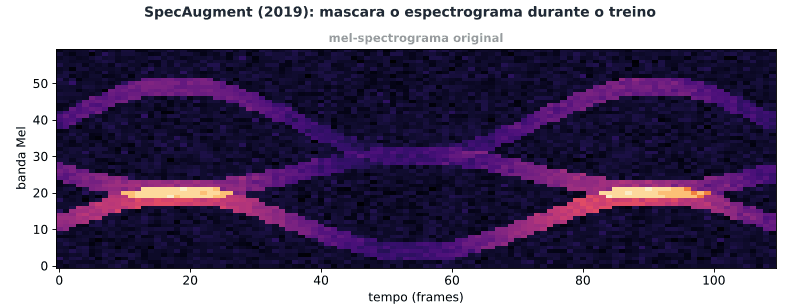

In [ ]:
# SpecAugment implementado a mao. Tres operacoes no mel-spec.

def spec_augment(mel_db, n_freq_masks=2, n_time_masks=2,
                  freq_mask_param=15, time_mask_param=20):
    '''SpecAugment simplificado: mascara aleatoria em tempo e frequencia.'''
    mel_aug = mel_db.copy()
    n_mels, n_frames = mel_aug.shape

    # Mascaras horizontais (zera faixas de frequencia)
    for _ in range(n_freq_masks):
        f = np.random.randint(0, freq_mask_param)
        f0 = np.random.randint(0, n_mels - f) if n_mels > f else 0
        mel_aug[f0:f0+f, :] = mel_aug.min()

    # Mascaras verticais (zera faixas de tempo)
    for _ in range(n_time_masks):
        t = np.random.randint(0, time_mask_param)
        t0 = np.random.randint(0, n_frames - t) if n_frames > t else 0
        mel_aug[:, t0:t0+t] = mel_aug.min()

    return mel_aug

mel_voz_aug = spec_augment(mel_voz_db.copy())

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
librosa.display.specshow(mel_voz_db, sr=sr_voz, hop_length=160,
                          x_axis="time", y_axis="mel", ax=axes[0], cmap="magma")
axes[0].set_title("Mel-spec original")

librosa.display.specshow(mel_voz_aug, sr=sr_voz, hop_length=160,
                          x_axis="time", y_axis="mel", ax=axes[1], cmap="magma")
axes[1].set_title("Apos SpecAugment, faixas mascaradas")

plt.tight_layout()
plt.show()

---
## Secao 11. Metricas WER e CER, e o teste de round trip

A metrica padrao para STT e o **Word Error Rate (WER)**. Dado uma transcricao de referencia *R* e a transcricao do modelo *H*, calcula-se a distancia de Levenshtein normalizada por numero de palavras. Substituicoes (S), delecoes (D) e insercoes (I) contam igual.

$$ \text{WER} = \frac{S + D + I}{N_{ref}} $$

WER abaixo de 5 por cento em audio limpo e considerado bom em sistemas comerciais. Em call center real, com sotaque, ruido e gírias, 15 a 25 por cento e a faixa tipica. A metrica complementar e **CER (Character Error Rate)**, que faz a mesma conta em caracteres. Util para linguas com palavras compostas (alemao, finlandes) onde uma palavra errada conta como erro inteiro no WER mas pode ter so um caractere errado.

Outras metricas relevantes:
- **MOS (Mean Opinion Score)**, escala 1 a 5, avaliacao humana, usado em TTS
- **RTF (Real Time Factor)**, razao entre tempo de processamento e duracao do audio. RTF abaixo de 1 significa mais rapido que tempo real, exigencia para streaming.

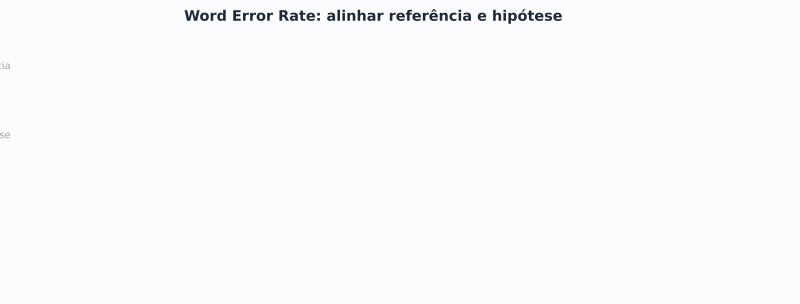

In [ ]:
# Round trip TTS para STT. Pega texto, sintetiza, transcreve, mede WER.
# Esse teste isola a degradacao introduzida pela cadeia, util para benchmarking.
from jiwer import wer, cer

def round_trip(texto_referencia, idioma="pt-br", whisper_lang="pt"):
    '''Sintetiza com gTTS, transcreve com Whisper, mede WER e CER.'''
    # Sintese
    gTTS(texto_referencia, lang=idioma).save("rt_tmp.mp3")
    y_rt, sr_rt = librosa.load("rt_tmp.mp3", sr=16000, mono=True)
    sf.write("rt_tmp.wav", y_rt, sr_rt)

    # Transcricao
    transcricao = modelo_whisper.transcribe("rt_tmp.wav",
                                             language=whisper_lang,
                                             fp16=(DEVICE.type == "cuda"))["text"].strip()

    # Metricas
    ref = texto_referencia.lower()
    hip = transcricao.lower()
    return {
        "referencia": texto_referencia,
        "transcricao": transcricao,
        "WER": wer(ref, hip),
        "CER": cer(ref, hip),
    }

teste = round_trip("Reconhecimento de fala converte audio em texto.")
print(f"Referencia:  {teste['referencia']}")
print(f"Transcricao: {teste['transcricao']}")
print(f"WER: {teste['WER']:.3f}, CER: {teste['CER']:.3f}")

In [ ]:
# Batch de frases para gerar estatistica. Em pt-BR com Whisper base,
# espere WER medio abaixo de 0.05 em audio gTTS limpo.

frases_teste = [
    "O modelo aprende a reconhecer padroes complexos na fala humana.",
    "Inteligencia artificial e o futuro da interacao entre pessoas e maquinas.",
    "A tecnologia de voz transforma o atendimento ao cliente nas empresas.",
    "Whisper e um modelo de transcricao multilingue criado pela OpenAI.",
    "A acuracia do reconhecimento depende da qualidade do audio de entrada.",
]

resultados_batch = []
for f in frases_teste:
    r = round_trip(f)
    resultados_batch.append(r)
    print(f"WER {r['WER']:.3f}  |  {r['transcricao']}")

wers = [r["WER"] for r in resultados_batch]
print()
print(f"WER medio: {np.mean(wers):.3f}, desvio padrao: {np.std(wers):.3f}")

In [ ]:
# Como o ruido de fundo afeta o WER. Mesmo audio em diferentes SNRs,
# transcrito pelo Whisper, com WER medido contra a referencia conhecida.

frase_snr = "Reconhecimento de fala converte audio em texto."
gTTS(frase_snr, lang="pt-br").save("snr_base.mp3")
y_snr, sr_snr = librosa.load("snr_base.mp3", sr=16000, mono=True)

print(f"{'SNR (dB)':>10s}  {'WER':>6s}  Transcricao")
print("-" * 80)
for snr in [30, 20, 15, 10, 5, 0]:
    y_n = adicionar_ruido_snr(y_snr, snr)
    sf.write("snr_tmp.wav", y_n, sr_snr)
    txt = modelo_whisper.transcribe("snr_tmp.wav", language="pt",
                                     fp16=(DEVICE.type == "cuda"))["text"].strip()
    erro = wer(frase_snr.lower(), txt.lower())
    print(f"{snr:>10d}  {erro:>6.3f}  {txt[:55]}")

### 11.1 A curva WER × SNR, plotada

O experimento acima imprime números; aqui mostramos a **curva**, que é como a degradação costuma ser reportada em papers e relatórios de produção. A faixa de SNR típica de um call center (5–15 dB) fica destacada.

In [ ]:
# Curva WER x SNR. Varre SNRs, transcreve com Whisper, plota.
frase_curva = "Reconhecimento de fala converte audio em texto."
gTTS(frase_curva, lang="pt-br").save("curva_base.mp3")
y_curva, sr_curva = librosa.load("curva_base.mp3", sr=16000, mono=True)

snrs = [30, 25, 20, 15, 10, 5, 0, -5]
wers_curva = []
for snr in snrs:
    y_n = adicionar_ruido_snr(y_curva, snr)
    sf.write("curva_tmp.wav", y_n, sr_curva)
    txt = modelo_whisper.transcribe("curva_tmp.wav", language="pt", fp16=(DEVICE.type == "cuda"))["text"].strip()
    wers_curva.append(wer(frase_curva.lower(), txt.lower()))

plt.figure(figsize=(11, 4))
plt.axvspan(5, 15, color="#F59E0B", alpha=0.15, label="faixa tipica de call center")
plt.plot(snrs, [w * 100 for w in wers_curva], "o-", color="#0B4F6C", lw=2, ms=7)
plt.axhline(5, color="#16A34A", ls="--", alpha=0.7, label="WER 5% (bom em producao)")
plt.gca().invert_xaxis()   # SNR alto (limpo) a esquerda -> baixo (sujo) a direita
plt.xlabel("SNR (dB) — esquerda = limpo, direita = ruidoso")
plt.ylabel("WER (%)")
plt.title("Degradacao do reconhecimento conforme o audio fica mais ruidoso")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print("Abaixo de ~10 dB de SNR, denoise dedicado (Secao 9) deixa de ser opcional.")

**Leitura do experimento.** A degradacao acompanha o decrescimo de SNR. Em call centers reais, voce frequentemente encontra SNR entre 5 e 15 dB. Por isso o pipeline padrao de producao inclui denoise dedicado antes do STT, exatamente como vimos na Secao 9. Em condicoes muito ruidosas (SNR proximo de zero), nenhum modelo, por melhor que seja, vai funcionar sem pre-processamento adequado.

---
## Secao 12. Esteganografia de audio, da teoria ao codigo escondido

A palavra **esteganografia** vem do grego *steganos* (coberto) e *graphein* (escrever). E a arte de esconder uma mensagem dentro de outra coisa, de modo que um observador casual nao perceba sequer que ha mensagem.

A historia comeca cedo. Herodoto, no seculo V antes de Cristo, descreve um general grego que raspou a cabeca de um escravo, tatuou a mensagem no couro cabeludo e esperou o cabelo crescer antes de envia-lo. No seculo XVII surgiram as tintas invisiveis. Na Segunda Guerra Mundial, os microdots alemaes condensavam paginas inteiras em pontos do tamanho de uma cabeca de alfinete.

A esteganografia digital nasce com o famoso paper de **Walter Bender, Daniel Gruhl, Norishige Morimoto e Anthony Lu**, publicado em 1996 no IBM Systems Journal (volume 35, numeros 3 e 4, paginas 313 a 336), com o titulo *Techniques for Data Hiding*. Bender, Lu e Morimoto eram do MIT Media Lab, Gruhl da IBM Research. O paper introduziu sistematicamente as quatro grandes familias de esteganografia em audio que ate hoje estruturam o campo. Vamos ver tres delas em codigo.

### 12.1 LSB coding, a familia mais simples

**Least Significant Bit (LSB) coding** explora o fato de que o bit menos significativo de uma amostra de audio em 16 bits representa uma variacao de amplitude da ordem de 1 parte em 32768. Imperceptivel ao ouvido humano. Se voce sobrescreve esse bit com a sua mensagem, o audio soa identico mas voce ganhou um canal de comunicacao oculto.

A regra geral: dada uma amostra *x*, voce zera o ultimo bit com `x AND 254` (porque 254 em binario e 11111110), e depois injeta o seu bit com `OR bit`. Para extrair, basta ler `x AND 1`. Para uma mensagem de N caracteres ASCII voce precisa de 8N amostras de audio, o que da muito espaco em qualquer arquivo WAV razoavel.

### Aviso de seguranca: o padrao que vamos demonstrar e o mesmo usado por malware real

A celula seguinte demonstra LSB escondendo **codigo Python que sera executado** com `exec()` na extracao. Isso e didaticamente poderoso porque mostra a tecnica completa, mas e exatamente o vetor de ataque usado por familias de malware reais.

Casos publicos documentados:

| Ano | Familia | Tecnica |
|---|---|---|
| 2014 | Stegoloader | Esteganografia em PNG para esconder payload em downloader |
| 2017 | Sundown EK | Esconde payload em imagens BMP corrompidas |
| 2019 | OceanLotus | APT vietnamita, esteganografia em PNG e WAV |
| 2020 | TurlaAPT | Grupo russo, payload encrypted em imagens hospedadas em GitHub |
| 2022 | Witchetty | APT chinesa, esteganografia em logo de Windows hospedado em Github |

A regra de seguranca a tirar daqui e clara. **Nunca execute conteudo extraido de arquivo sem auditoria humana**. Em codigo de producao, jamais alimente diretamente um `exec()`, `eval()`, `subprocess` ou `pickle.loads()` com bytes derivados de input externo. O que vamos rodar abaixo so e seguro porque controlamos tanto o injetor quanto o extrator, e o payload e visivel no codigo. Em qualquer outro contexto, esse padrao seria abertura de porta para execucao de codigo arbitrario.

In [ ]:
# LSB coding com payload executavel.
# A mensagem escondida e codigo Python que sera executado na extracao.
# DEMONSTRACAO PEDAGOGICA APENAS. Nao replique esse padrao em producao.

import wave

# Payload que sera escondido no LSB. Quando extraido e executado,
# imprime uma listagem do diretorio e uma mensagem.
payload_code = '''
import subprocess
print('--- comando linux executado a partir do audio ---')
resultado = subprocess.check_output(['ls', '-l'], text=True)
print(resultado)
print('--- HELLO WORLD a partir do payload ---')
'''

def injetar_payload(caminho_saida, codigo_secreto):
    '''Cria um audio de 440 Hz com codigo Python escondido nos bits menos significativos.'''
    # Gera tom de 440 Hz, 3 segundos, 44100 Hz, 16 bits.
    sample_rate = 44100
    duracao = 3.0
    t_local = np.linspace(0, duracao, int(sample_rate * duracao))
    sinal_audio = (np.sin(2 * np.pi * 440 * t_local) * 32767).astype(np.int16)

    # Convertemos para bytes para manipular cada byte individualmente.
    frames = bytearray(sinal_audio.tobytes())

    # Adicionamos um marcador '###' ao fim do payload para o decodificador
    # saber onde a mensagem termina (alem disso o LSB do resto do audio
    # contera lixo aleatorio que nao corresponde a caracteres validos).
    codigo_secreto = codigo_secreto + "###"

    # Converte cada caractere ASCII em 8 bits, formando a string binaria.
    binary_payload = "".join(format(ord(c), "08b") for c in codigo_secreto)

    # Para cada bit do payload, sobrescreve o LSB de uma amostra do audio.
    # frames[i] & 254 zera o ultimo bit (11111110 em binario)
    # | int(bit) injeta o bit do payload
    for i in range(len(binary_payload)):
        frames[i] = (frames[i] & 254) | int(binary_payload[i])

    # Salva como WAV 16 bits mono.
    with wave.open(caminho_saida, "wb") as out:
        out.setnchannels(1)
        out.setsampwidth(2)
        out.setframerate(sample_rate)
        out.writeframes(frames)

    print(f"Arquivo '{caminho_saida}' gerado com payload oculto no LSB.")

injetar_payload("stego_audio.wav", payload_code)

In [ ]:
# Extracao e execucao do payload.
# Le os bits LSB de cada byte, reagrupa em caracteres, executa o codigo.

def extrair_e_executar(caminho_audio):
    # Le todos os bytes do audio (sample frames em 16 bits = 2 bytes por amostra)
    with wave.open(caminho_audio, "rb") as wav:
        frames = bytearray(list(wav.readframes(wav.getnframes())))

    # Extrai o bit menos significativo de cada byte.
    bits_extraidos = [str(frames[i] & 1) for i in range(len(frames))]

    # Agrupa de 8 em 8 bits para formar bytes, converte para ASCII.
    bytes_str = ["".join(bits_extraidos[i:i+8])
                  for i in range(0, len(bits_extraidos), 8)]

    decoded = ""
    for byte in bytes_str:
        if len(byte) < 8:
            break
        decoded += chr(int(byte, 2))
        # Para ao encontrar o marcador de fim.
        if "###" in decoded:
            break

    codigo_final = decoded.replace("###", "")

    print("Tocando o audio original (perceptualmente igual a um tom de 440 Hz):")
    display(Audio(caminho_audio))

    print()
    print("Codigo Python recuperado do LSB:")
    print("=" * 50)
    print(codigo_final)
    print("=" * 50)
    print()
    print("Executando o codigo extraido (DEMONSTRACAO CONTROLADA APENAS):")
    print("-" * 50)

    # exec interpreta a string como codigo Python.
    # Em producao isso seria proibido. Aqui controlamos completamente o payload.
    try:
        exec(codigo_final)
    except Exception as e:
        print(f"Erro ao executar codigo extraido: {e}")

extrair_e_executar("stego_audio.wav")

**O que voce acabou de ver.** Um tom puro de 440 Hz, perceptualmente indistinguivel de qualquer outro tom puro, carregou em si codigo Python funcional. O ouvinte humano nao tem como saber que existe mensagem ali. Esse e o poder e o perigo da esteganografia LSB. A defesa em sistemas reais nao e tentar detectar o LSB no audio (e dificil), e sim nunca executar bytes que vem de arquivos.

### 12.2 Esteganografia visual no espectrograma

Uma variante interessante e desenhar texto diretamente no espectrograma do audio. O som soa como ruido distribuido em uma faixa de frequencias, mas se voce abrir o espectrograma vai ver a mensagem como uma figura. Essa tecnica foi popularizada por Aphex Twin em 1999, na faixa *Equation* do album *Windowlicker*, em que o autorretrato do musico aparece quando voce visualiza o espectrograma. Venetian Snares fez algo parecido em 2001 em *Look*.

Em termos tecnicos, voce renderiza o texto como imagem em escala de cinza. Cada pixel define a amplitude de uma frequencia em um instante. Soma de senoides ponderadas pelos pixels gera o audio final.

In [ ]:
# Esteganografia visual: desenha texto direto no espectrograma.
# Compatibilidade com matplotlib 3.9+: usa buffer_rgba() em vez do antigo tostring_rgb().

from scipy.io import wavfile as scipy_wavfile

def gerar_espectrograma_textual(texto, filename="espectro_oculto.wav"):
    '''Sintetiza audio que, no espectrograma, mostra o texto desenhado.'''
    fs = 44100
    duracao = 3.0
    f_min, f_max = 500, 5000  # faixa de frequencia onde a mensagem aparece

    # Cria uma imagem temporaria com o texto desenhado em preto sobre fundo branco
    fig_tmp, ax_tmp = plt.subplots(figsize=(10, 4))
    ax_tmp.text(0.5, 0.5, texto, fontsize=50, ha="center", va="center", weight="bold")
    ax_tmp.axis("off")
    fig_tmp.canvas.draw()

    # Converte a imagem para array RGBA, depois para escala de cinza.
    # buffer_rgba() retorna formato (height, width, 4) com canal alpha.
    rgba = np.asarray(fig_tmp.canvas.buffer_rgba())
    gray = np.dot(rgba[..., :3], [0.2989, 0.5870, 0.1140])
    # Inverte verticalmente porque a coordenada de imagem cresce de cima para baixo
    # mas a frequencia no espectrograma cresce de baixo para cima.
    gray = np.flipud(gray)
    # Tambem inverte intensidade: texto preto deve virar amplitude alta no audio.
    gray = 255 - gray
    plt.close(fig_tmp)

    # Cada linha da imagem corresponde a uma frequencia entre f_min e f_max.
    t_local = np.linspace(0, duracao, int(fs * duracao))
    sinal = np.zeros_like(t_local)

    n_linhas, n_colunas = gray.shape
    freqs_alvo = np.linspace(f_min, f_max, n_linhas)

    print("Sintetizando audio. Isso leva alguns segundos pela varredura de frequencias...")
    for i, freq_atual in enumerate(freqs_alvo):
        # A intensidade de cada coluna define a amplitude da senoide naquele instante.
        envelope = np.interp(np.linspace(0, n_colunas, len(t_local)),
                             np.arange(n_colunas), gray[i, :])
        sinal += envelope * np.sin(2 * np.pi * freq_atual * t_local)

    # Normaliza para evitar clipping.
    sinal = sinal / np.max(np.abs(sinal))
    scipy_wavfile.write(filename, fs, (sinal * 32767).astype(np.int16))
    print(f"Audio gerado: {filename}")

gerar_espectrograma_textual("HELLO WORLD")

In [ ]:
# Visualizando o resultado. Reproduza o audio (vai soar como ruido modulado)
# e abra o espectrograma. O texto aparece desenhado.

y_oculto, sr_oculto = librosa.load("espectro_oculto.wav", sr=None)
print("Audio: soa como ruido distribuido em frequencias medias.")
display(Audio(y_oculto, rate=sr_oculto))

# Espectrograma em dB
D = librosa.amplitude_to_db(np.abs(librosa.stft(y_oculto)), ref=np.max)

plt.figure(figsize=(12, 6))
librosa.display.specshow(D, sr=sr_oculto, x_axis="time", y_axis="linear", cmap="magma")
plt.ylim(0, 6000)
plt.title("Espectrograma do audio. A mensagem esta visivel.")
plt.colorbar(format="%+2.0f dB")
plt.show()

### 12.3 Echo hiding e spread spectrum

Em 1996, no Information Hiding Workshop em Cambridge, **Daniel Gruhl, Anthony Lu e Walter Bender** publicaram *Echo Hiding* (Lecture Notes in Computer Science 1174, paginas 295 a 315). A tecnica codifica bits introduzindo ecos curtos de 1 a 2 ms no audio, com amplitude muito baixa. O ouvido humano integra esses ecos no som principal e nao percebe a presenca da copia. A vantagem do echo hiding sobre o LSB e a robustez. Echo hiding sobrevive a compressao MP3, ao contrario do LSB simples.

Em 1997, **Ingemar Cox, Joe Kilian, Tom Leighton e Talal Shamoon** publicaram no IEEE Transactions on Image Processing (volume 6, numero 12) *Secure Spread Spectrum Watermarking for Multimedia*. A tecnica e originaria das telecomunicacoes militares, onde sinais sao espalhados em uma banda larga de frequencias com baixa amplitude em cada frequencia. Em audio, a marca d agua aparece como uma camada de ruido tao baixa que e indistinguivel do ruido ambiente, mas com correlacao matematica que so quem tem a chave consegue detectar. E uma das tecnicas mais robustas, sobrevive a compressao, a re-gravacao analogica, a corte e recolagem.

### 12.4 A era neural: AudioSeal 2024 e SynthID

Em janeiro de 2024, **Robin San Roman, Pierre Fernandez, Teddy Furon, Alexandre Defossez, Tuan Tran e Hady Elsahar**, todos da Meta AI, publicaram *Proactive Detection of Voice Cloning with Localized Watermarking* (arXiv:2401.17264). O paper foi aceito no ICML 2024 e a implementacao open source esta disponivel sob licenca MIT em `github.com/facebookresearch/audioseal`.

A arquitetura do **AudioSeal** e composta por duas redes neurais treinadas conjuntamente. Um gerador produz uma marca d agua imperceptivel a ser somada ao audio. Um detector localiza a marca ate o nivel da amostra, em 16 kHz isso e uma resolucao temporal de 1/16000 de segundo. Os autores reportam acuracia de 90 a 100 por cento na deteccao apos transformacoes comuns: MP3, AAC, ruido aditivo, time stretch, pitch shift. E duas ordens de grandeza mais rapido que o WavMark, baseline anterior.

Em paralelo, o **Google DeepMind** lancou em 2024 o SynthID Audio, integrado ao Lyria (modelo de musica generativa) e ao NotebookLM (sintese de podcast). A tecnica explora mascaramento psicoacustico para esconder a marca em regioes onde o ouvido nao percebe. Em janeiro de 2026, o Google publicou o SynthID Detector publico, um portal web onde qualquer pessoa pode submeter audio para verificacao. Ate o momento do lancamento, mais de dez bilhoes de pecas de conteudo ja haviam sido marcadas com SynthID nos servicos do Google.

O caso de uso central dessas duas tecnologias e detectar clonagem de voz e deepfake. Se um audio circula online dizendo ser do presidente, mas nao contem marca AudioSeal ou SynthID, ja e sinal de alerta. Se contem marca, pode-se rastrear a origem. E o equivalente em audio do que SynthID Image faz para imagens geradas por Imagen e Midjourney.

**Por que isso importa.** Se um áudio viral afirma ser de uma autoridade mas **não** carrega marca AudioSeal nem SynthID, isso já é um sinal de alerta; se carrega, dá para rastrear a origem. É o equivalente, em áudio, do SynthID para imagens do Imagen. Em janeiro de 2026 o Google abriu o **SynthID Detector** público, e mais de 10 bilhões de conteúdos já haviam sido marcados. A tendência regulatória (EU AI Act, entre outros) caminha para **exigir** marcação de conteúdo sintético, então marca d'água de áudio deixou de ser curiosidade e virou requisito de produto.

---
## Secao 13. Caso integrador, o reCAPTCHA de audio

Vamos amarrar tudo que foi visto ate aqui em um unico caso. Em agosto de 2017, **Kevin Bock, Daven Patel, George Hughey e Dave Levin**, da Universidade de Maryland, publicaram no 11th USENIX Workshop on Offensive Technologies (WOOT 17) o paper *unCaptcha: A Low-Resource Defeat of reCaptcha's Audio Challenge*. O artigo esta disponivel publicamente em `uncaptcha.cs.umd.edu/papers/uncaptcha_woot17.pdf`.

O reCAPTCHA do Google e usado por centenas de milhares de sites como primeira linha contra automacao. Para usuarios com deficiencia visual, ha uma alternativa de audio: o sistema toca uma sequencia de digitos falados e o usuario digita o que ouviu. Esse fluxo foi alvo da pesquisa de Bock e colegas.

### 13.1 O pipeline do unCaptcha em seis etapas

O pipeline tecnico do paper original mapeia exatamente nas seis etapas que voce viu ao longo deste notebook. Note como cada etapa que estudamos academicamente aparece aqui em um sistema integrado real.

| Etapa do unCaptcha | Onde voce viu isso no notebook | Tecnica |
|---|---|---|
| 1. Captura do desafio de audio (MP3) | Secao 6 | Download via HTTP, conversao para WAV |
| 2. Segmentacao por silencio | Secao 9, denoise | Detectar regioes de baixa energia, cortar em palavras |
| 3. Extracao de features | Secao 5, mel-spec, MFCC | Implicita nos motores STT chamados em seguida |
| 4. Modelo acustico | Secao 8, Whisper, DeepSpeech | Seis motores STT comerciais usados em paralelo |
| 5. Mapeamento fonetico | Logica de pos-processamento | Homofonos como too, two, to, 2 todos viram digito 2 |
| 6. Ensemble por voto ponderado | Tecnica classica de ML | Combina respostas dos seis motores com peso por confianca |

Resultados experimentais reportados no paper:
- **450 desafios** coletados de sites em producao
- **85,15 por cento de acerto**
- **5,42 segundos** de tempo medio por desafio
- **Zero modelos** treinados pelos autores, apenas API calls

Em 2018, apos o Google modificar o reCAPTCHA para usar frases ditas em vez de digitos isolados, a equipe lancou o **unCaptcha2**, com aproximadamente 90 por cento de acuracia. O codigo esta no repositorio `github.com/ecthros/uncaptcha2`. O Google avaliou o ataque como fora do escopo do programa de bug bounty mas autorizou a publicacao do codigo, em um protocolo de divulgacao responsavel padrao de seis meses entre comunicacao e publicacao.

### 13.2 Por que esse caso e didaticamente perfeito

Tres motivos. Primeiro, o pipeline contem todas as etapas do nosso capitulo, em ordem natural. Segundo, os autores nao treinaram nenhum modelo, apenas combinaram criativamente componentes existentes. Isso reforca uma licao importante para engenharia de produto: muitas vezes o valor esta na composicao, nao na invencao. Terceiro, o caso teve consequencia direta no mercado. O Google passou a investir pesado em reCAPTCHA v3 (telemetria comportamental, sem desafio explicito) e em defesas adversariais como **aaeCAPTCHA** (Hossen e Hei, 2022) e **Yeehaw Junction** (Abdullah et al., NDSS 2022), que usam exemplos adversariais de audio como CAPTCHA: o humano ouve uma palavra simples mas o STT transcreve outra coisa.

### 13.3b O pipeline que o mercado realmente roda: call center ponta a ponta

O unCaptcha é ótimo como *mapa* das etapas, mas o pipeline que você vai de fato construir em produção é o de **atendimento**. Ele usa exatamente os mesmos blocos desta aula, na ordem natural, e a célula abaixo o executa de ponta a ponta num áudio sintético com ruído: **VAD → denoise → STT → métricas**. É o esqueleto de qualquer produto de transcrição de call center.

In [ ]:
# Pipeline de call center ponta a ponta, reaproveitando tudo que vimos.
# Simula uma ligacao ruidosa: fala em pt-BR + ruido de fundo tipo "ar condicionado".

frase_call = ("Bom dia, eu gostaria de verificar o saldo da minha conta e "
              "tambem a fatura do cartao de credito deste mes.")
gTTS(frase_call, lang="pt-br").save("call.mp3")
y_call, sr_call = librosa.load("call.mp3", sr=16000, mono=True)
y_call = adicionar_ruido_snr(y_call, snr_db=10)   # SNR 10 dB = call center tipico
sf.write("call_ruidoso.wav", y_call, sr_call)

def pipeline_call_center(caminho, referencia):
    """VAD -> denoise -> STT -> metricas. Retorna o texto final e o WER em cada etapa."""
    y, sr_p = librosa.load(caminho, sr=16000, mono=True)
    etapas = {}

    # 1) STT direto no audio sujo (baseline)
    txt_sujo = modelo_whisper.transcribe(caminho, language="pt", fp16=(DEVICE.type == "cuda"))["text"].strip()
    etapas["1. bruto (sem tratamento)"] = (txt_sujo, wer(referencia.lower(), txt_sujo.lower()))

    # 2) Denoise + STT
    y_limpo = nr.reduce_noise(y=y, sr=sr_p, prop_decrease=0.85)
    y_limpo = librosa.util.normalize(y_limpo)
    sf.write("call_limpo.wav", y_limpo, sr_p)
    txt_limpo = modelo_whisper.transcribe("call_limpo.wav", language="pt", fp16=(DEVICE.type == "cuda"))["text"].strip()
    etapas["2. apos denoise"] = (txt_limpo, wer(referencia.lower(), txt_limpo.lower()))

    # 3) VAD (recorta fala) + denoise + STT  -- mais robusto em audios com muito silencio
    try:
        from silero_vad import load_silero_vad, get_speech_timestamps, collect_chunks
        mv = load_silero_vad()
        ts = get_speech_timestamps(y_limpo.astype(np.float32), mv, sampling_rate=sr_p)
        if ts:
            import torch
            y_vad = collect_chunks(ts, torch.tensor(y_limpo)).numpy()
            sf.write("call_vad.wav", y_vad, sr_p)
            txt_vad = modelo_whisper.transcribe("call_vad.wav", language="pt", fp16=(DEVICE.type == "cuda"))["text"].strip()
            etapas["3. apos VAD + denoise"] = (txt_vad, wer(referencia.lower(), txt_vad.lower()))
    except Exception as e:
        print(f"(etapa VAD pulada: {str(e)[:50]})")

    return etapas

print("Audio da ligacao (ruidoso, SNR ~10 dB):")
display(Audio(y_call, rate=sr_call))
print()

resultado_call = pipeline_call_center("call_ruidoso.wav", frase_call)
print(f"{'etapa':28s} {'WER':>7s}   transcricao")
print("-" * 95)
for etapa, (txt, erro) in resultado_call.items():
    print(f"{etapa:28s} {erro:7.3f}   {txt[:50]}")

**O que observar.** Em geral o WER cai a cada etapa: denoise limpa o sinal, VAD remove silêncio que confunde o modelo. Em produção real, acrescentam-se ainda duas camadas depois do STT: um **LLM** para corrigir pontuação e jargão do domínio, e **diarização** (quem falou quando) para separar cliente e atendente. Cada camada tem responsabilidade clara, o que facilita o *debug* quando algo degrada.

### 13.4 Defesas modernas e o que vem depois

Apos a publicacao do unCaptcha em 2017 e da versao 2 em 2018, a comunidade respondeu com novos esquemas defensivos. Dois merecem destaque.

**aaeCAPTCHA** (Md Imran Hossen e Xiali Hei, Universidade de Louisiana em Lafayette, 2022, arXiv:2203.02735). A ideia inverte o ataque adversarial. Em vez do atacante usar perturbacoes para enganar o ASR (
Automatic Speech Recognition), e o servico de CAPTCHA que gera audio com perturbacao adversarial. O humano ouve a palavra normal (zero, um, dois) e digita corretamente. O STT transcreve outra coisa por causa da perturbacao otimizada. Avaliado contra cinco ASR baseados em DNN e tres STT comerciais (Google, Amazon, Microsoft), com alta robustez.

**Yeehaw Junction** (Hadi Abdullah, Aditya Karlekar, Vincent Bindschaedler, Patrick Traynor, Universidade da Florida, NDSS 2022, arXiv:2203.05408). Usa o *Kenansville Attack* como gerador de ruido adversarial transferivel. Resiste ao WaveGuard, mecanismo de defesa contra adversariais.

Em paralelo, o **reCAPTCHA v3** abandonou completamente o desafio explicito. Hoje, o Google avalia o usuario por sinais de comportamento: padrao de movimento do mouse, tempo de digitacao, fingerprint do browser, historico de navegacao. O score retornado e um numero entre 0 e 1, e o site decide o que fazer. Audio CAPTCHA tradicional virou caso de borda para acessibilidade, e ja nao e linha primaria de defesa.

---
## Seção 13.5. 🎧 App ao vivo: fale, transcreva e sintetize de volta

Para fechar a parte prática no espírito das lives anteriores, este app junta síntese e reconhecimento num só lugar, acessível pelo celular via QR code. O aluno grava a voz no navegador, o Whisper transcreve, e o gTTS lê o texto de volta — fechando o ciclo **voz → texto → voz** que é a base de qualquer assistente.

In [ ]:
# App Gradio: gravar voz -> transcrever (Whisper) -> re-sintetizar (gTTS).
# Em Colab, expõe uma URL publica automaticamente (share=True).
try:
    import gradio as gr

    def transcrever_e_sintetizar(caminho_audio):
        if caminho_audio is None:
            return "Grave ou envie um audio primeiro.", None
        # STT
        texto = modelo_whisper.transcribe(caminho_audio, language="pt", fp16=(DEVICE.type == "cuda"))["text"].strip()
        # TTS de volta
        if texto:
            gTTS(texto, lang="pt-br").save("app_resposta.mp3")
            return texto, "app_resposta.mp3"
        return "(nada reconhecido)", None

    with gr.Blocks(title="Voz: STT + TTS ao vivo") as app_voz:
        gr.Markdown("# 🎙️ Fale e veja a maquina entender\n"
                    "Grave sua voz. O Whisper transcreve e o gTTS le de volta.")
        with gr.Row():
            entrada = gr.Audio(sources=["microphone", "upload"], type="filepath", label="Sua voz")
            with gr.Column():
                saida_txt = gr.Textbox(label="Transcricao (Whisper)", lines=3)
                saida_audio = gr.Audio(label="Sintese de volta (gTTS)")
        gr.Button("Transcrever e sintetizar", variant="primary").click(
            transcrever_e_sintetizar, entrada, [saida_txt, saida_audio])

    app_voz.launch(server_name="127.0.0.1", share=False, prevent_thread_lock=True)   # share=True gera URL publica; em Colab aparece o link
except Exception as e:
    print(f"Gradio indisponivel ({str(e)[:80]}). Instale com: pip install gradio")

---
## Secao 14. Sintese final e referencias

O percurso deste notebook seguiu uma trilha cronologica e topologica. Comecamos em 1822 com Fourier, atravessamos as decadas dos sintetizadores eletronicos, da era HMM, da revolucao do deep learning em 2012, e chegamos ate AudioSeal e Whisper em 2024. Em cada parada, a teoria saiu do texto e virou codigo executavel. O ponto que vale levar para casa nao e a lista de tecnicas, e sim a percepcao de que cada bloco resolve uma fatia diferente do problema, e que projetos reais combinam varios blocos.

Em um call center moderno, sua pipeline tipica e:
- denoise leve por DL para limpar o audio
- VAD para descartar silencio
- STT (Whisper, Wav2Vec, ou API comercial) para transcrever
- modelo de linguagem ou LLM para corrigir e estruturar
- esteganografia opcional (AudioSeal, SynthID) caso voce gere audio de volta para o cliente

Cada uma dessas camadas tem decada de pesquisa publica por tras. O profissional que entende o porque de cada camada existir e o porque de cada tecnica ter o trade-off que tem e justamente o profissional que toma boas decisoes de arquitetura quando algo nao funciona como esperado.

### Referencias completas

**Sintese e reconhecimento de fala**
- Davis, K. H., Biddulph, R., Balashek, S. (1952). *Automatic Recognition of Spoken Digits*. JASA 24(6), 637-642.
- Davis, S. B., Mermelstein, P. (1980). *Comparison of parametric representations for monosyllabic word recognition*. IEEE TASSP 28(4), 357-366.
- Rabiner, L. R. (1989). *A Tutorial on Hidden Markov Models and Selected Applications in Speech Recognition*. Proceedings of the IEEE 77(2), 257-286.
- Hinton, G. et al. (2012). *Deep Neural Networks for Acoustic Modeling in Speech Recognition*. IEEE Signal Processing Magazine 29(6), 82-97.
- Hannun, A. et al. (2014). *Deep Speech: Scaling up end-to-end speech recognition*. arXiv:1412.5567.
- van den Oord, A. et al. (2016). *WaveNet: A Generative Model for Raw Audio*. arXiv:1609.03499.
- Wang, Y. et al. (2017). *Tacotron: Towards End-to-End Speech Synthesis*. arXiv:1703.10135.
- Baevski, A. et al. (2020). *wav2vec 2.0*. NeurIPS 2020.
- Radford, A. et al. (2022). *Robust Speech Recognition via Large-Scale Weak Supervision*. arXiv:2212.04356.
- Park, D. et al. (2019). *SpecAugment*. Interspeech 2019.

**Reducao de ruido**
- Boll, S. F. (1979). *Suppression of Acoustic Noise in Speech Using Spectral Subtraction*. IEEE TASSP 27(2), 113-120.
- Ephraim, Y., Malah, D. (1984). *Speech Enhancement Using a MMSE Short-Time Spectral Amplitude Estimator*. IEEE TASSP 32(6), 1109-1121.
- Valin, J.-M. (2018). *A Hybrid DSP/Deep Learning Approach to Real-Time Full-Band Speech Enhancement*. IEEE MMSP Workshop. arXiv:1709.08243.
- Defossez, A., Synnaeve, G., Adi, Y. (2020). *Real Time Speech Enhancement in the Waveform Domain*. Interspeech 2020.

**Esteganografia e marca d agua**
- Bender, W., Gruhl, D., Morimoto, N., Lu, A. (1996). *Techniques for data hiding*. IBM Systems Journal 35(3-4), 313-336.
- Gruhl, D., Lu, A., Bender, W. (1996). *Echo Hiding*. In Information Hiding (LNCS 1174), pp. 295-315.
- Cox, I. J., Kilian, J., Leighton, F. T., Shamoon, T. (1997). *Secure Spread Spectrum Watermarking*. IEEE Trans. Image Processing 6(12), 1673-1687.
- San Roman, R., Fernandez, P., Furon, T., Defossez, A., Tran, T., Elsahar, H. (2024). *Proactive Detection of Voice Cloning with Localized Watermarking*. arXiv:2401.17264. ICML 2024.

**Ataques e defesas**
- Bock, K., Patel, D., Hughey, G., Levin, D. (2017). *unCaptcha: A Low-Resource Defeat of reCaptcha's Audio Challenge*. USENIX WOOT 17.
- Carlini, N., Wagner, D. (2018). *Audio Adversarial Examples: Targeted Attacks on Speech-to-Text*. arXiv:1801.01944.
- Zhang, G. et al. (2017). *DolphinAttack: Inaudible Voice Commands*. ACM CCS 2017.
- Hossen, M. I., Hei, X. (2022). *aaeCAPTCHA*. arXiv:2203.02735.
- Abdullah, H. et al. (2022). *Attacks as Defenses* (Yeehaw Junction). NDSS 2022. arXiv:2203.05408.

**Livros e tutoriais**
- Jurafsky, D., Martin, J. H. *Speech and Language Processing*. 3a edicao, em desenvolvimento, capitulos disponiveis em web.stanford.edu/~jurafsky/slp3.
- McFee, B. et al. (2015). *librosa: Audio and Music Signal Analysis in Python*. SciPy 2015.